# Lab 1 code
Note that this document focuses strictly on code implementation of the laboratory. For experiments discussions and detailed analysis, please refer to the accompanying project report.

## Initialization
In this section we import the proper libraries and define a seed

In [1]:
import copy, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, ConfusionMatrixDisplay

SEED = 42
DATA_PATH = "dataset_lab_1.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

cuda


## Task 1: Preprocessing
We first define the function `prepare_data`, which purpose is to clean the dataset. The function processes the raw dataset by replacing infinite values with NaNs, dropping missing records, and removing duplicate rows. The `drop_port` and `drop_duplicates` will help in following tasks by dropping the destination port feature as well as the duplicates. Data is finally split into 70% training, 15% validation, and 15% test sets using stratified sampling to preserve original class proportions.



In [2]:
def prepare_data(csv_path, drop_port=False, drop_duplicates=True, seed=SEED):
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    counts = {"raw": df["Label"].value_counts()}

    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    counts["after_nan"] = df["Label"].value_counts()
    if drop_port:
        df = df.drop(columns=["Destination Port"])
    if drop_duplicates:
        df = df.drop_duplicates()
    counts["after_clean"] = df["Label"].value_counts()

    le = LabelEncoder()
    y = le.fit_transform(df["Label"].values)
    feature_names = [c for c in df.columns if c != "Label"]
    X = df[feature_names].values

    Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=seed, stratify=ytmp)

    scaler = StandardScaler().fit(Xtr)
    raw = dict(train=Xtr, val=Xva, test=Xte)
    return dict(
        Xraw=raw,
        X={k: scaler.transform(v) for k, v in raw.items()},
        y=dict(train=ytr, val=yva, test=yte),
        class_names=list(le.classes_), feature_names=feature_names,
        scaler=scaler, counts=pd.DataFrame(counts))

Concerning Task 3, we clean the dataset without optional parameters to use the full cleaning stages

In [3]:
D = prepare_data(DATA_PATH)
print('Data before and after pre processing')
display(D["counts"])

print('\nDistribution of samples across classes')
split_summary = pd.DataFrame(
    [{"Split": k.capitalize(), "Samples": len(v)} for k, v in D["y"].items()]
)
display(split_summary)

Data before and after pre processing


,raw,after_nan,after_clean
Label,,,
Benign,20000,19992,19242
Brute Force,1507,1507,1427
DoS Hulk,5000,4982,3868
PortScan,5000,4999,4849



Distribution of samples across classes


,Split,Samples
0,Train,20570
1,Val,4408
2,Test,4408


## Helper functions
To help us with the following experiments, we define a set of auxiliary utility functions:
The model architecture and optimization setup are managed by `build_model` and `build_optimizer`, which dynamically construct multi-layer perceptrons with configurable hidden dimensions, activation functions, dropout rates, and batch normalization alongside AdamW or SGD optimizers. Data ingestion is handled by `make_loaders`, converting data splits into PyTorch DataLoader instances with deterministic seed generators. Model training is executed through `fit`, which manages the training loop, tracks training and validation loss and macro-F1 scores, applies early stopping, and restores the best model checkpoint. Finally, `run_experiment` unifies the entire execution workflow by applying hyperparameter overrides, computing class-balanced loss weights when required, evaluating models on the validation set, and visualizing loss and metric curves via `plot_run`.


In [4]:
def build_model(n_in, n_out, hidden_sizes=(64,), activation="relu", dropout=0.0, batchnorm=False):
    acts = {"relu": nn.ReLU, "linear": nn.Identity}
    layers, prev = [], n_in
    for h in hidden_sizes:
        layers.append(nn.Linear(prev, h))
        if batchnorm: layers.append(nn.BatchNorm1d(h))
        layers.append(acts[activation]())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, n_out))
    return nn.Sequential(*layers)

def build_optimizer(params, name, lr, weight_decay, momentum):
    if name == "adamw": return optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":   return optim.SGD(params, lr=lr, momentum=momentum)
    raise ValueError(name)

def make_loaders(data, scale, batch_size, seed):
    X = data["X"] if scale else data["Xraw"]
    mk = lambda s: TensorDataset(torch.tensor(X[s], dtype=torch.float32),
                                 torch.tensor(data["y"][s], dtype=torch.long))
    g = torch.Generator().manual_seed(seed)
    return (DataLoader(mk("train"), batch_size=batch_size, shuffle=True, generator=g),
            DataLoader(mk("val"), batch_size=1024, shuffle=False))

def evaluate(model, loader, criterion):
    model.eval(); loss_sum, preds, labs = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out, y).item() * x.size(0)
            preds.append(out.argmax(1).cpu().numpy()); labs.append(y.cpu().numpy())
    return loss_sum / len(loader.dataset), np.concatenate(labs), np.concatenate(preds)

def fit(model, train_loader, val_loader, criterion, optimizer, epochs, patience, min_delta, restore_best=True):
    h = dict(train_loss=[], val_loss=[], val_f1=[])
    best, best_state, best_epoch, wait, t0 = float("inf"), None, 0, 0, time.time()
    for ep in range(epochs):
        model.train(); run = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            run += loss.item() * x.size(0)
        h["train_loss"].append(run / len(train_loader.dataset))
        vl, vt, vp = evaluate(model, val_loader, criterion)
        h["val_loss"].append(vl)
        h["val_f1"].append(f1_score(vt, vp, average="macro", zero_division=0))
        if vl < best - min_delta:
            best, best_epoch, wait = vl, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    if restore_best and best_state is not None: model.load_state_dict(best_state)
    h.update(best_epoch=best_epoch, n_epochs=len(h["train_loss"]), time_s=time.time() - t0)
    return h

DEFAULTS = dict(scale=True, hidden_sizes=(64,), activation="relu", dropout=0.0, batchnorm=False,
                optimizer="adamw", lr=5e-4, weight_decay=0.01, momentum=0.0,
                batch_size=64, epochs=100, patience=10, min_delta=1e-5,
                class_weight=None, seed=SEED, restore_best=True)

def run_experiment(task, change, data=None, plot=True, **overrides):
    """Executes single experiment pipeline and displays clear metrics tables and heatmap."""
    unknown = set(overrides) - set(DEFAULTS)
    assert not unknown, f"unknown parameters: {unknown}"
    cfg = {**DEFAULTS, **overrides}
    data = data or D
    names, n_cls = data["class_names"], len(data["class_names"])

    set_seed(cfg["seed"])
    tr, va = make_loaders(data, cfg["scale"], cfg["batch_size"], cfg["seed"])
    n_in = next(iter(tr))[0].shape[1]
    model = build_model(n_in, n_cls, cfg["hidden_sizes"], cfg["activation"],
                        cfg["dropout"], cfg["batchnorm"]).to(device)
    w = None
    if cfg["class_weight"] == "balanced":
        c = np.bincount(data["y"]["train"], minlength=n_cls)
        w = torch.tensor(len(data["y"]["train"]) / (n_cls * c), dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=w)
    opt = build_optimizer(model.parameters(), cfg["optimizer"], cfg["lr"],
                          cfg["weight_decay"], cfg["momentum"])

    h = fit(model, tr, va, criterion, opt, cfg["epochs"], cfg["patience"], cfg["min_delta"], cfg["restore_best"])

    vl, vt, vp = evaluate(model, va, nn.CrossEntropyLoss())

    # Output
    print(f"=== {task} | {change} ===")

    report_dict = classification_report(vt, vp, target_names=names, digits=3, zero_division=0, output_dict=True)
    accuracy_val = report_dict.pop("accuracy")

    print(f"Overall Accuracy: {accuracy_val:.3f}\n")
    report_df = pd.DataFrame(report_dict).T.round(3)
    display(report_df)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(vt, vp)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=names)
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {task}")
    plt.grid(False)
    plt.show()

    # Plotting
    if plot:
      print(f"Best epoch: {h['best_epoch']}")
      plot_run(h, f"{task}\n{change}")

    return dict(model=model, hist=h, cfg=cfg, y_true=vt, y_pred=vp)

def plot_run(h, title, logy=False):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["val_loss"], label="Val")
    ax[0].axvline(h["best_epoch"], ls="--", color="gray", label="Best epoch")
    ax[0].set(xlabel="Epoch", ylabel="Loss", title=title); ax[0].legend(); ax[0].grid(alpha=.3)
    if logy: ax[0].set_yscale("log")
    ax[1].plot(h["val_f1"], color="green"); ax[1].axvline(h["best_epoch"], ls="--", color="gray")
    ax[1].set(xlabel="Epoch", ylabel="Macro-F1 (val)", title="Macro-F1 validation"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

## Task 2
In this task, we test our framework with very simple examples. We mainly use the `run_experiment` function for this and future tasks.

### Task 2A
In this task, we try our first simple baseline. This baseline is described by the default configuration of the `run_experiment` function

=== Task 2A | baseline: 1x64, ReLU, AdamW lr=5e-4, batch 64 ===
Overall Accuracy: 0.952



,precision,recall,f1-score,support
Benign,0.964,0.967,0.966,2886.0
Brute Force,0.762,0.944,0.843,214.0
DoS Hulk,0.983,0.924,0.953,580.0
PortScan,0.950,0.915,0.932,728.0
macro avg,0.915,0.938,0.924,4408.0
weighted avg,0.954,0.952,0.952,4408.0


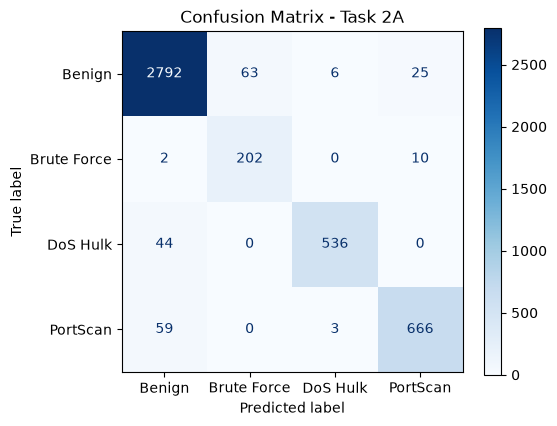

Best epoch: 97


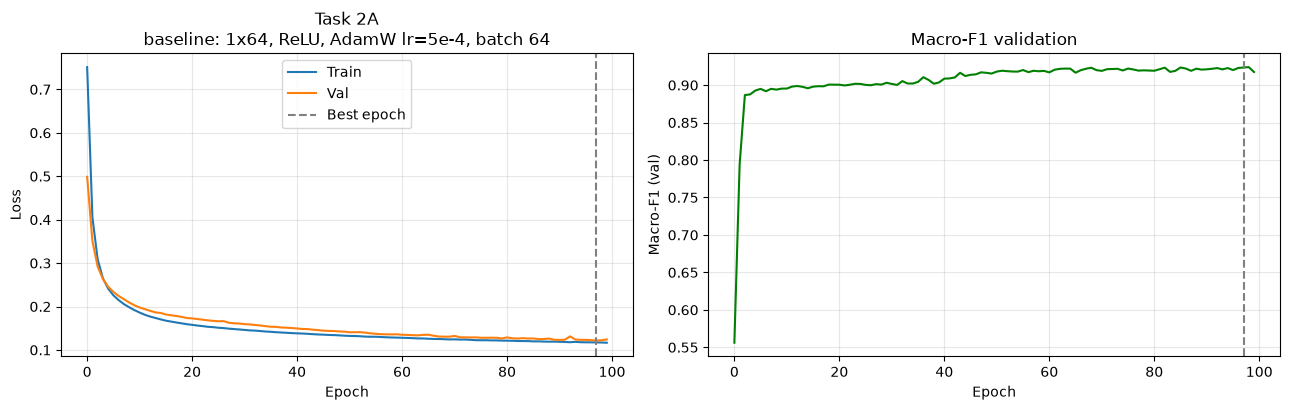

In [6]:
r1 = run_experiment("Task 2A", "baseline: 1x64, ReLU, AdamW lr=5e-4, batch 64")

### Task 2B
Each run of this subtask will implement a different wrong way to modify the model, as specified in the lab document

First, we remove feature scaling

=== Task 2B | S1: no scaling ===
Overall Accuracy: 0.916



,precision,recall,f1-score,support
Benign,0.973,0.909,0.940,2886.0
Brute Force,0.666,0.893,0.762,214.0
DoS Hulk,0.814,0.867,0.840,580.0
PortScan,0.895,0.993,0.941,728.0
macro avg,0.837,0.915,0.871,4408.0
weighted avg,0.924,0.916,0.918,4408.0


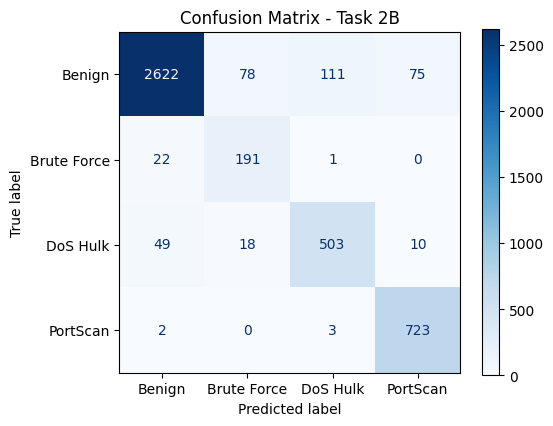

Best epoch: 10


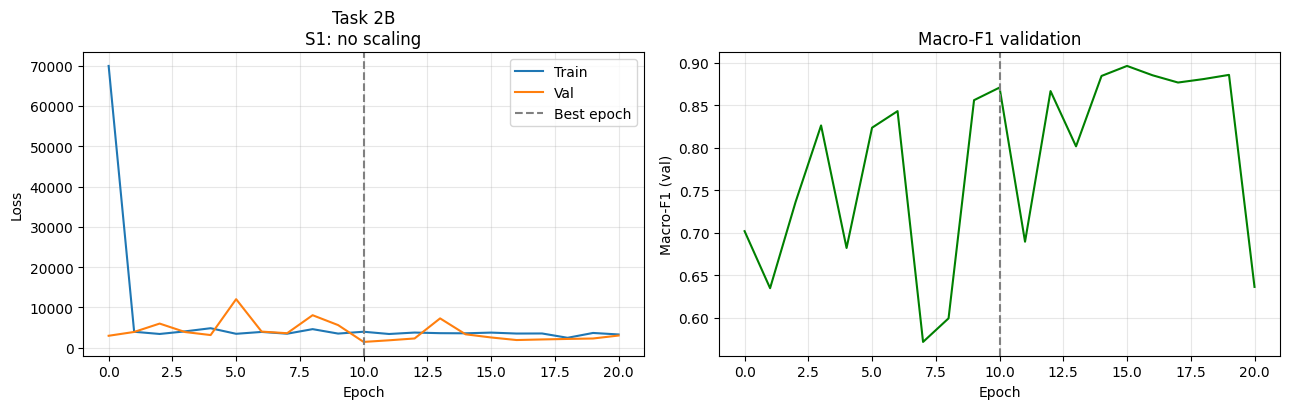

In [ ]:
r2 = run_experiment("Task 2B", "S1: no scaling", scale=False)

Then, we increase the learning rate

=== Task 2B | S2: lr 5e-4 -> 0.5 ===
Overall Accuracy: 0.902



,precision,recall,f1-score,support
Benign,0.892,0.972,0.930,2886.0
Brute Force,0.667,0.037,0.071,214.0
DoS Hulk,0.984,0.857,0.916,580.0
PortScan,0.892,0.918,0.905,728.0
macro avg,0.859,0.696,0.705,4408.0
weighted avg,0.893,0.902,0.882,4408.0


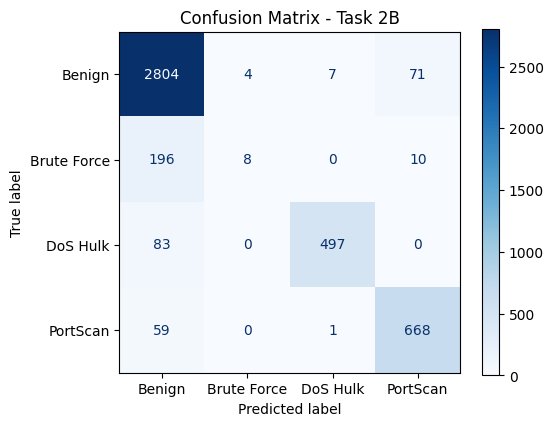

Best epoch: 9


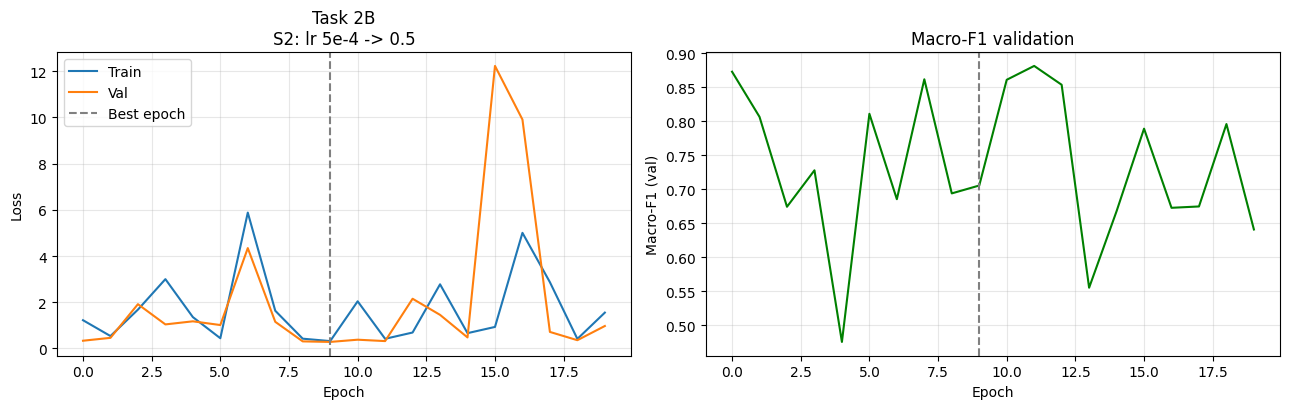

In [ ]:
r3 = run_experiment("Task 2B", "S2: lr 5e-4 -> 0.5", lr=0.5)

Finally, we try the opposite: we lower the learning rate

=== Task 2B | S3: lr 5e-4 -> 5e-6 (/100) ===
Overall Accuracy: 0.798



,precision,recall,f1-score,support
Benign,0.767,0.994,0.866,2886.0
Brute Force,0.000,0.000,0.000,214.0
DoS Hulk,0.986,0.824,0.898,580.0
PortScan,0.939,0.232,0.372,728.0
macro avg,0.673,0.513,0.534,4408.0
weighted avg,0.787,0.798,0.747,4408.0


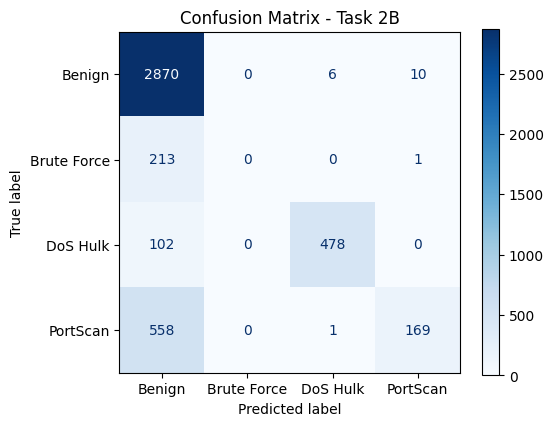

Best epoch: 99


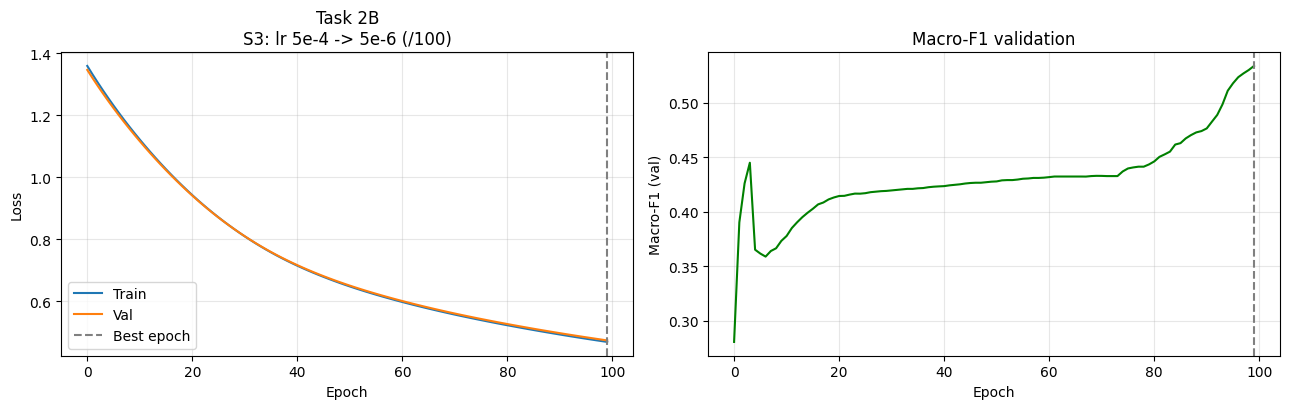

In [ ]:
r4 = run_experiment("Task 2B", "S3: lr 5e-4 -> 5e-6 (/100)", lr=5e-6)

### Task 2C
In this task we train the model again by increasing its epochs, allowing it to converge better. We set this new model as our baseline

=== Task 2C | baseline: epochs 100 -> 300 ===
Overall Accuracy: 0.961



,precision,recall,f1-score,support
Benign,0.966,0.979,0.972,2886.0
Brute Force,0.894,0.944,0.918,214.0
DoS Hulk,0.975,0.926,0.950,580.0
PortScan,0.949,0.920,0.934,728.0
macro avg,0.946,0.942,0.944,4408.0
weighted avg,0.961,0.961,0.960,4408.0


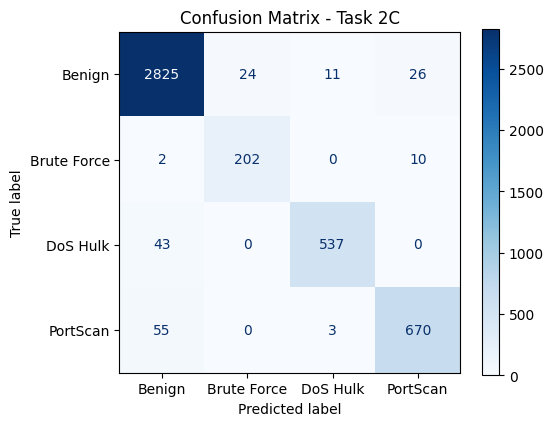

Best epoch: 208


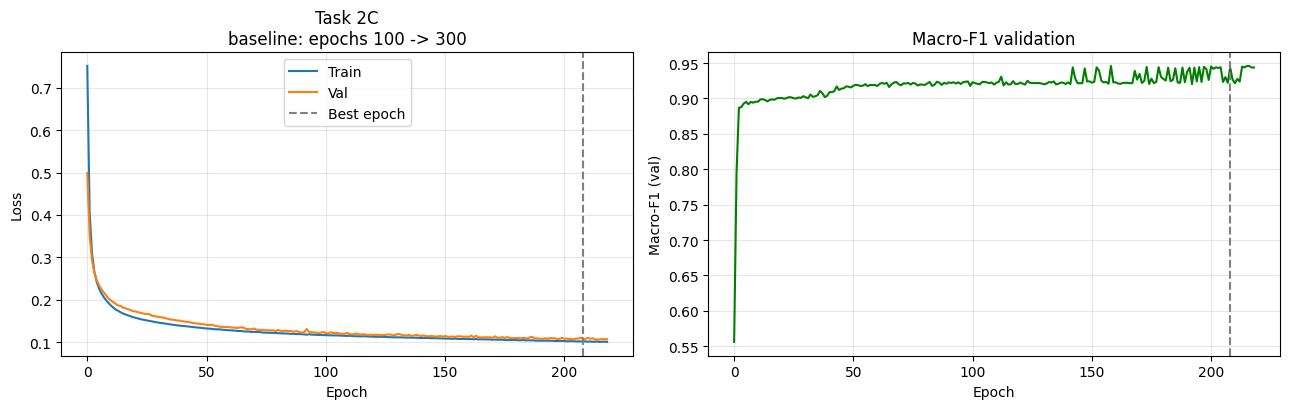

In [ ]:
r5 = run_experiment("Task 2C", "baseline: epochs 100 -> 300", epochs=300)
BASE = r5

To evaluate the performance of the new model on the test set, we define a new function `eval_split`, that specifically evaluates the model on the validation or test split without training.

In [ ]:
def eval_split(model, data, split="test", scale=True, verbose=True):
    X = (data["X"] if scale else data["Xraw"])[split]
    y = data["y"][split]
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    loss, yt, yp = evaluate(model, DataLoader(ds, batch_size=1024, shuffle=False),
                            nn.CrossEntropyLoss())
    names = data["class_names"]
    if verbose:
        print(f"--- {split.upper()} (loss {loss:.4f}) ---")
        report_dict = classification_report(yt, yp, target_names=names, digits=3, zero_division=0, output_dict=True)
        report_df = pd.DataFrame(report_dict).T
        report_df.index.name = None
        display(report_df.round(3))

        cm = confusion_matrix(yt, yp)
        cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=names)
        cmd.plot(cmap="Blues", xticks_rotation="vertical")
        plt.show()

    return dict(
        loss=loss,
        macro_f1=f1_score(yt, yp, average="macro"),
        recall=recall_score(yt, yp, average=None, labels=range(len(names)), zero_division=0)
    )


We then ran the evaluation on the validation set and the test set, filling the performance gap. A minimal performance gap confirms that the model generalizes well to unseen network traffic and has not overfitted to the validation set.

--- VAL (loss 0.1061) ---


,precision,recall,f1-score,support
Benign,0.966,0.979,0.972,2886.000
Brute Force,0.894,0.944,0.918,214.000
DoS Hulk,0.975,0.926,0.950,580.000
PortScan,0.949,0.920,0.934,728.000
accuracy,0.961,0.961,0.961,0.961
macro avg,0.946,0.942,0.944,4408.000
weighted avg,0.961,0.961,0.960,4408.000


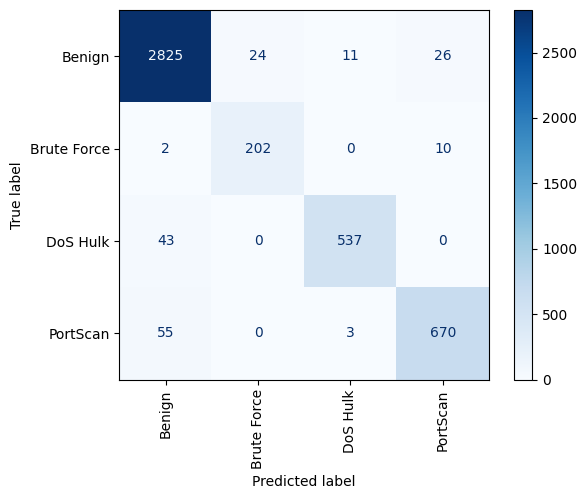

--- TEST (loss 0.1124) ---


,precision,recall,f1-score,support
Benign,0.969,0.977,0.973,2887.000
Brute Force,0.898,0.944,0.920,214.000
DoS Hulk,0.980,0.936,0.958,580.000
PortScan,0.935,0.923,0.929,727.000
accuracy,0.961,0.961,0.961,0.961
macro avg,0.945,0.945,0.945,4408.000
weighted avg,0.961,0.961,0.961,4408.000


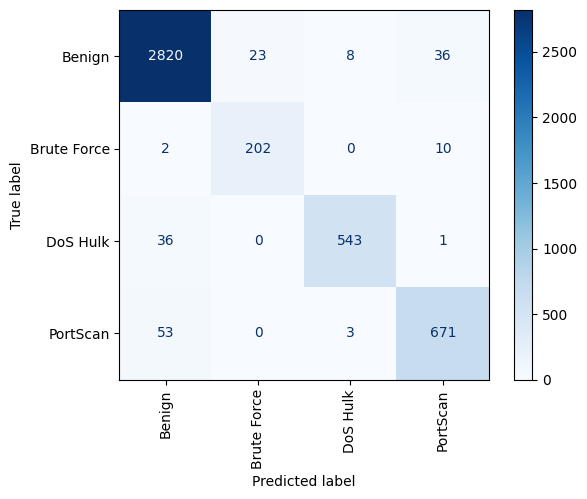

Comparison table


,val,test,gap
loss,0.1061,0.1124,0.0063
macro_F1,0.9436,0.9449,0.0013
recall_Benign,0.9789,0.9768,-0.0021
recall_Brute Force,0.9439,0.9439,0.0000
recall_DoS Hulk,0.9259,0.9362,0.0103
recall_PortScan,0.9203,0.9230,0.0027


In [ ]:
# Evaluate final model on validation split
val_res = eval_split(BASE["model"], D, "val")

# Evaluate final model on test split
test_res = eval_split(BASE["model"], D, "test")

cmp = pd.DataFrame({
    "val": [val_res["loss"], val_res["macro_f1"], *val_res["recall"]],
    "test": [test_res["loss"], test_res["macro_f1"], *test_res["recall"]]
}, index=["loss", "macro_F1"] + [f"recall_{n}" for n in D["class_names"]]).round(4)

cmp["gap"] = (cmp["test"] - cmp["val"]).round(4)
cmp.index.name = None

print ("Comparison table")
display(cmp)

Since the gaps are negligible, we decided to lock the new model `r5` as our new baseline. Furthermore, we switched the activation function from ReLu to linear (as asked by the lab document)

=== Task 2C | activation: ReLU -> linear ===
Overall Accuracy: 0.881



,precision,recall,f1-score,support
Benign,0.893,0.943,0.918,2886.0
Brute Force,0.471,0.037,0.069,214.0
DoS Hulk,0.992,0.853,0.918,580.0
PortScan,0.780,0.905,0.838,728.0
macro avg,0.784,0.685,0.686,4408.0
weighted avg,0.867,0.881,0.863,4408.0


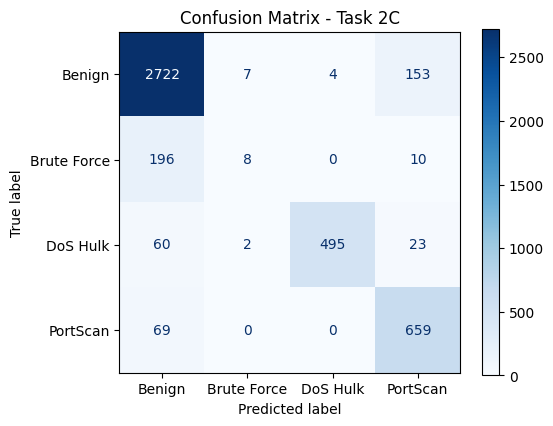

Best epoch: 78


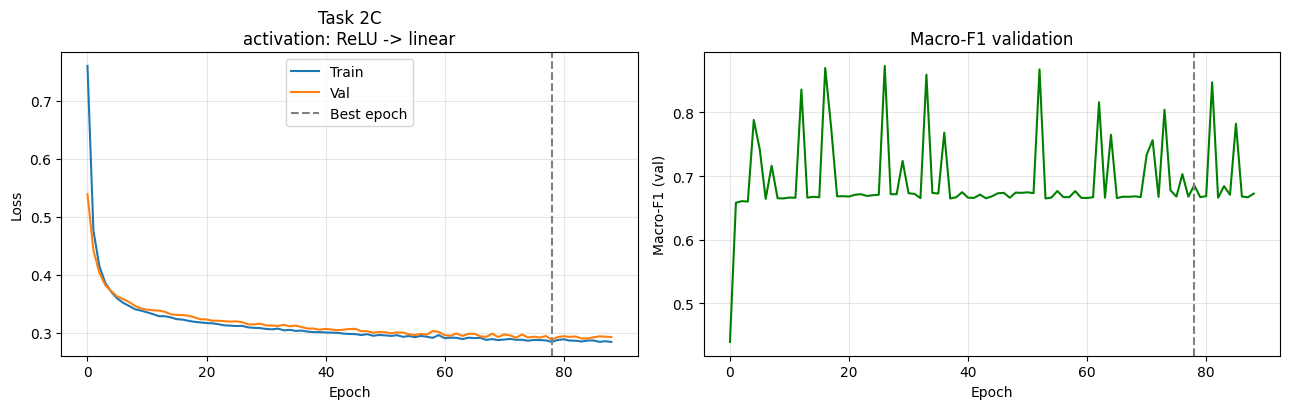

In [ ]:
BASE_OVERRIDES = dict(epochs=300)

r6 = run_experiment("Task 2C", "activation: ReLU -> linear", activation="linear", **BASE_OVERRIDES)

## Task 3
The objective of this section is to determine whether certain attack types (e.g., port scan) are strongly correlated with specific destination port numbers. Identifying this correlation reveals whether the model might heavily rely on port numbers rather than behavioral network traffic features and checks if the port distributions in the test set mirror those seen during training.

In [ ]:
port_idx = D["feature_names"].index("Destination Port")
names = D["class_names"]
bf = names.index("Brute Force")
Xtr_raw, ytr = D["Xraw"]["train"], D["y"]["train"]

for c, n in enumerate(names):
    p = Xtr_raw[ytr == c, port_idx]
    top = pd.Series(p).value_counts(normalize=True).head(3).round(3).to_dict()
    print(f"{n:12s} n={len(p):5d} | % on port 80 = {np.mean(p == 80):.3f} | top ports: {top}")

ben = names.index("Benign")
print("Benign on port 80:", int((Xtr_raw[ytr == ben, port_idx] == 80).sum()),
      "| on port 8080:", int((Xtr_raw[ytr == ben, port_idx] == 8080).sum()))
print("Brute Force ports in test set:", np.unique(D["Xraw"]["test"][D["y"]["test"] == bf, port_idx]))

Benign       n=13469 | % on port 80 = 0.105 | top ports: {53.0: 0.43, 443.0: 0.234, 80.0: 0.105}
Brute Force  n=  999 | % on port 80 = 1.000 | top ports: {80.0: 1.0}
DoS Hulk     n= 2708 | % on port 80 = 1.000 | top ports: {80.0: 1.0}
PortScan     n= 3394 | % on port 80 = 0.001 | top ports: {16001.0: 0.003, 5631.0: 0.003, 2602.0: 0.003}
Benign on port 80: 1413 | on port 8080: 4
Brute Force ports in test set: [80.]


This next test modifies all Brute Force test samples targeting port 80 by reassigning them to port 8080, creating a modified version of our dataset

In [ ]:


Xte_cf = D["Xraw"]["test"].copy()
mask = (D["y"]["test"] == bf) & (Xte_cf[:, port_idx] == 80)

print("BF samples shifted to 8080:", int(mask.sum()), "out of", int((D["y"]["test"] == bf).sum()))

Xte_cf[mask, port_idx] = 8080
Xte_cf_scaled = D["scaler"].transform(Xte_cf)

BF samples shifted to 8080: 214 out of 214


We then define the `eval_arrays` function as a utility that evaluates a trained PyTorch model directly on arrays without manual tensor conversion. It displays clean per-class metric tables and plots the confusion matrix. With this function, we evaluate the model on the modified dataset, performing a counterfactual test

Evaluation Loss: 0.4202 | Accuracy: 0.917 | Macro F1: 0.727



,precision,recall,f1-score,support
Benign,0.909,0.977,0.942,2887.0
Brute Force,0.303,0.047,0.081,214.0
DoS Hulk,0.980,0.936,0.958,580.0
PortScan,0.935,0.923,0.929,727.0


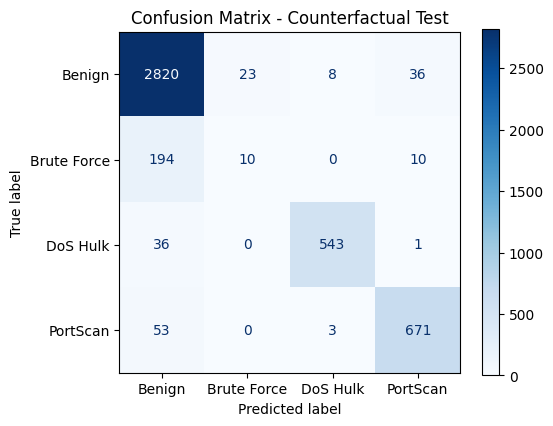

In [ ]:
def eval_arrays(model, X, y, names):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    loss, yt, yp = evaluate(model, DataLoader(ds, batch_size=1024, shuffle=False), nn.CrossEntropyLoss())

    report_dict = classification_report(yt, yp, target_names=names, digits=3, zero_division=0, output_dict=True)
    acc = report_dict.pop("accuracy")
    macro_avg = report_dict.pop("macro avg")
    weighted_avg = report_dict.pop("weighted avg")

    print(f"Evaluation Loss: {loss:.4f} | Accuracy: {acc:.3f} | Macro F1: {macro_avg['f1-score']:.3f}\n")

    report_df = pd.DataFrame(report_dict).T.round(3)
    display(report_df)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(yt, yp)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=names)
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    plt.title("Confusion Matrix - Counterfactual Test")
    plt.grid(False)
    plt.show()

    return yt, yp

yt, yp = eval_arrays(BASE["model"], Xte_cf_scaled, D["y"]["test"], names)

### Task 3: Dataset Class Distribution Analysis
The code below details the class counts, sample proportions, and retention ratios for the modified dataset and puts them in comparison to the ones of the datasets across all stages of pre processing

In [ ]:
D_dup   = prepare_data(DATA_PATH, drop_port=True, drop_duplicates=False)
D_nodup = prepare_data(DATA_PATH, drop_port=True, drop_duplicates=True)

tab = pd.DataFrame({
    "raw":                  D["counts"]["raw"],
    "with port":    D["counts"]["after_clean"],
    "no port":    D_dup["counts"]["after_clean"],
    "no port + dedup":      D_nodup["counts"]["after_clean"]
})
tab.loc["TOTAL"] = tab.sum()
tab.index.name = None

print("Class Counts Across Preprocessing Pipeline:")
display(tab)

proportions_df = (tab / tab.loc["TOTAL"]).round(3)
print("\nClass Proportions:")
display(proportions_df)

retention_series = (1-tab["no port + dedup"] / tab["with port"]).round(3)
retention_df = retention_series.to_frame(name="Drop Ratio")
print("Variation")
display(retention_df)

Class Counts Across Preprocessing Pipeline:


,raw,with port,no port,no port + dedup
Benign,20000,19242,19992,16889
Brute Force,1507,1427,1507,1427
DoS Hulk,5000,3868,4982,3868
PortScan,5000,4849,4999,285
TOTAL,31507,29386,31480,22469



Class Proportions:


,raw,with port,no port,no port + dedup
Benign,0.635,0.655,0.635,0.752
Brute Force,0.048,0.049,0.048,0.064
DoS Hulk,0.159,0.132,0.158,0.172
PortScan,0.159,0.165,0.159,0.013
TOTAL,1.000,1.000,1.000,1.000


Variation


,Drop Ratio
Benign,0.122
Brute Force,0.000
DoS Hulk,0.000
PortScan,0.941
TOTAL,0.235


We define `D2` as the sanitized dataset without the destination port feature and with deduplication applied. The dataset `D2` will be used for the rest of the lab

In [ ]:
D2 = D_nodup

classes = D2["class_names"]
split_dist = pd.DataFrame({
    "Train": np.bincount(D2["y"]["train"], minlength=len(classes)),
    "Val":   np.bincount(D2["y"]["val"], minlength=len(classes)),
    "Test":  np.bincount(D2["y"]["test"], minlength=len(classes))
}, index=classes)

split_dist["Total"] = split_dist.sum(axis=1)
split_dist.loc["TOTAL"] = split_dist.sum(axis=0)
split_dist.index.name = None

print("Class Distribution Across Splits (D2):")
display(split_dist)


Class Distribution Across Splits (D2):


,Train,Val,Test,Total
Benign,11822,2533,2534,16889
Brute Force,999,214,214,1427
DoS Hulk,2708,580,580,3868
PortScan,199,43,43,285
TOTAL,15728,3370,3371,22469


## Task 4
The objective of this task is to see how the new dataset affects our model.

Firstly, we run our baseline using the new dataset `D2`


=== Task 4 | Baseline on dataset without Destination Port (D2) ===
Overall Accuracy: 0.953



,precision,recall,f1-score,support
Benign,0.966,0.976,0.971,2533.0
Brute Force,0.809,0.930,0.865,214.0
DoS Hulk,0.981,0.905,0.942,580.0
PortScan,0.531,0.395,0.453,43.0
macro avg,0.822,0.801,0.808,3370.0
weighted avg,0.953,0.953,0.953,3370.0


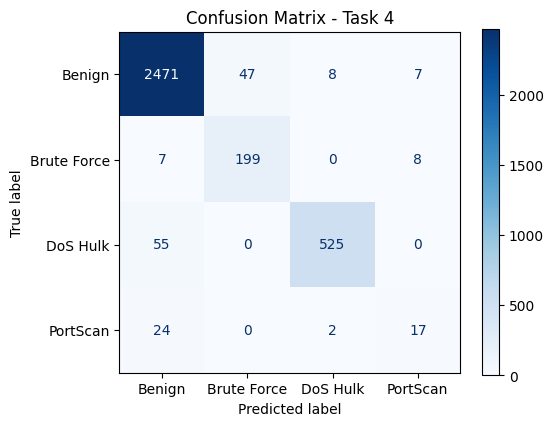

Best epoch: 72


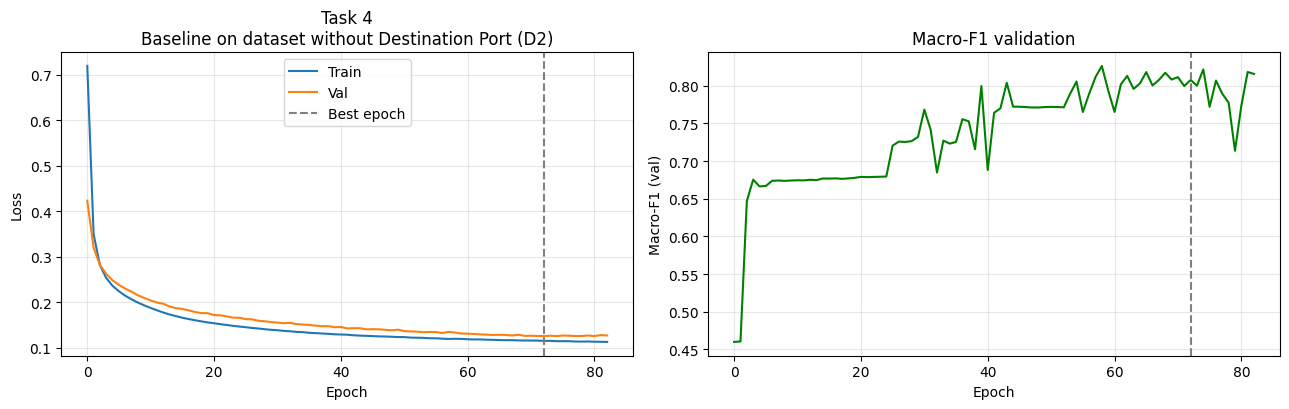

In [ ]:
r7 = run_experiment("Task 4", "Baseline on dataset without Destination Port (D2)", data=D2, **BASE_OVERRIDES)

Then, we change our loss function to a cross weight entropy loss (balanced) and train again

=== 4B | Weighted Loss (balanced) ===
Overall Accuracy: 0.915



,precision,recall,f1-score,support
Benign,0.988,0.912,0.949,2533.0
Brute Force,0.774,0.944,0.851,214.0
DoS Hulk,0.957,0.916,0.936,580.0
PortScan,0.191,0.953,0.318,43.0
macro avg,0.727,0.931,0.763,3370.0
weighted avg,0.959,0.915,0.932,3370.0


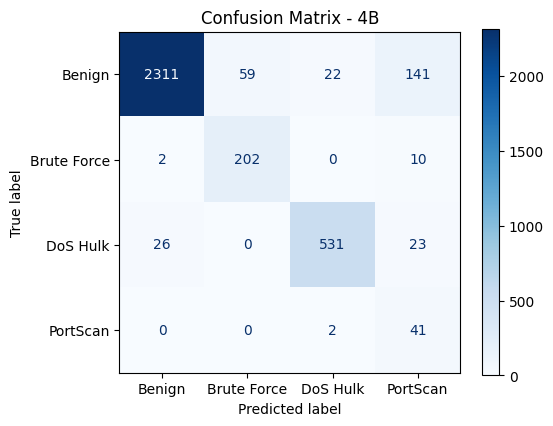

Best epoch: 87


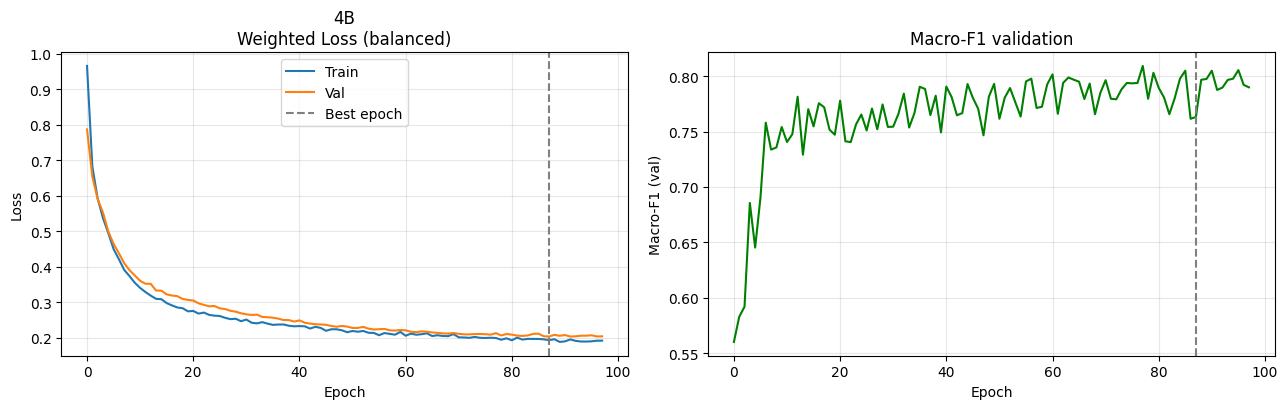

In [ ]:
r8 = run_experiment("4B", "Weighted Loss (balanced)", data=D2, class_weight="balanced", **BASE_OVERRIDES)

## Task 5
In this task, we evaluate if more complex models can beat our baseline.

We establish a new baseline. It maintains the exact model architecture and hyperparameters as the original setup, modified only by adjusting the loss function to handle class imbalance (it is the same model used in the last section of Task 4)

In [ ]:
T5 = dict(class_weight="balanced", **BASE_OVERRIDES)

### Task 5A
We train three models, each one with different hidden layer structures.

The first model has two hidden layers, of sizes `(64,32)`

=== 5A | Hidden Layers: (64,32) ===
Overall Accuracy: 0.923



,precision,recall,f1-score,support
Benign,0.991,0.919,0.954,2533.0
Brute Force,0.762,0.944,0.843,214.0
DoS Hulk,0.933,0.929,0.931,580.0
PortScan,0.233,0.953,0.374,43.0
macro avg,0.730,0.937,0.776,3370.0
weighted avg,0.956,0.923,0.935,3370.0


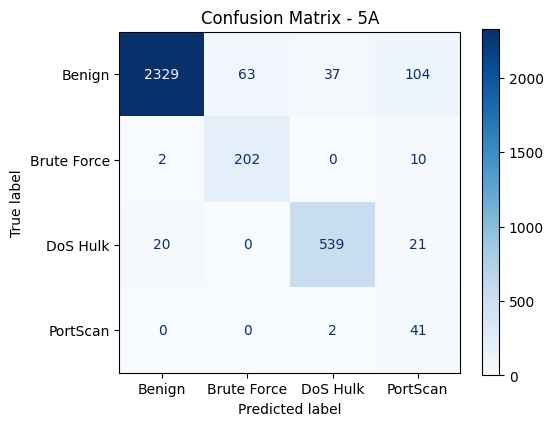

Best epoch: 54


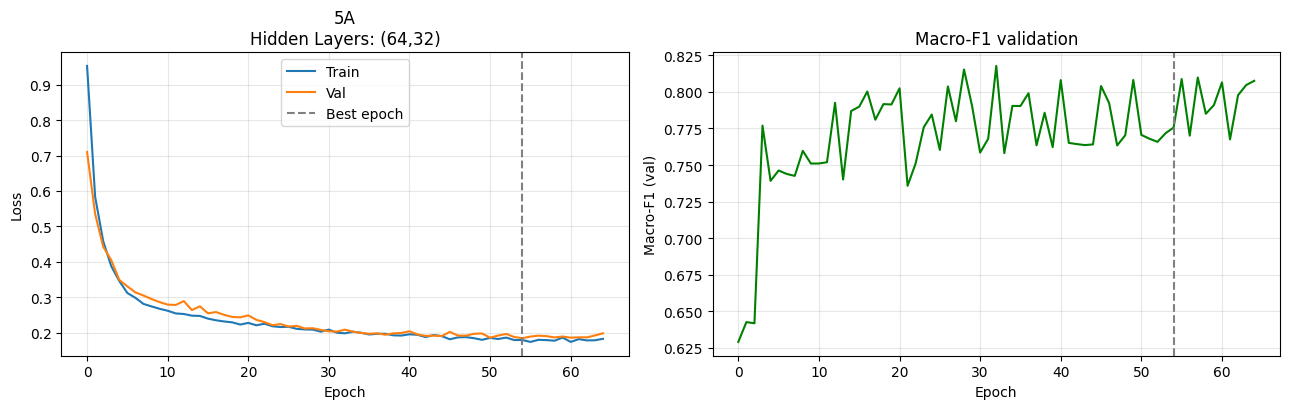

In [ ]:
r9 = run_experiment("5A", "Hidden Layers: (64,32)", data=D2, hidden_sizes=(64, 32), **T5)

The second has three hidden layers, of sizes `(64,32,16)`

=== 5A | Hidden Layers (64,32,16) ===
Overall Accuracy: 0.903



,precision,recall,f1-score,support
Benign,0.993,0.893,0.940,2533.0
Brute Force,0.760,0.949,0.844,214.0
DoS Hulk,0.944,0.928,0.936,580.0
PortScan,0.161,0.953,0.275,43.0
macro avg,0.714,0.931,0.749,3370.0
weighted avg,0.959,0.903,0.925,3370.0


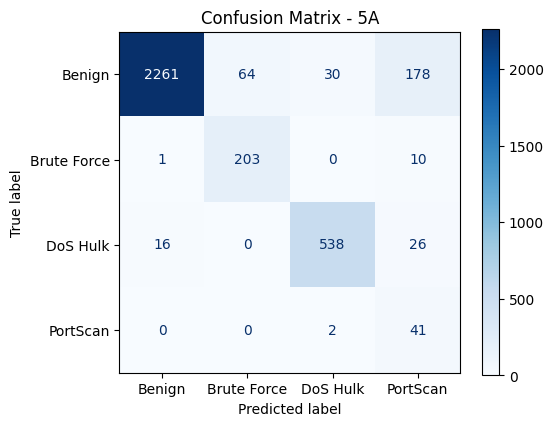

Best epoch: 72


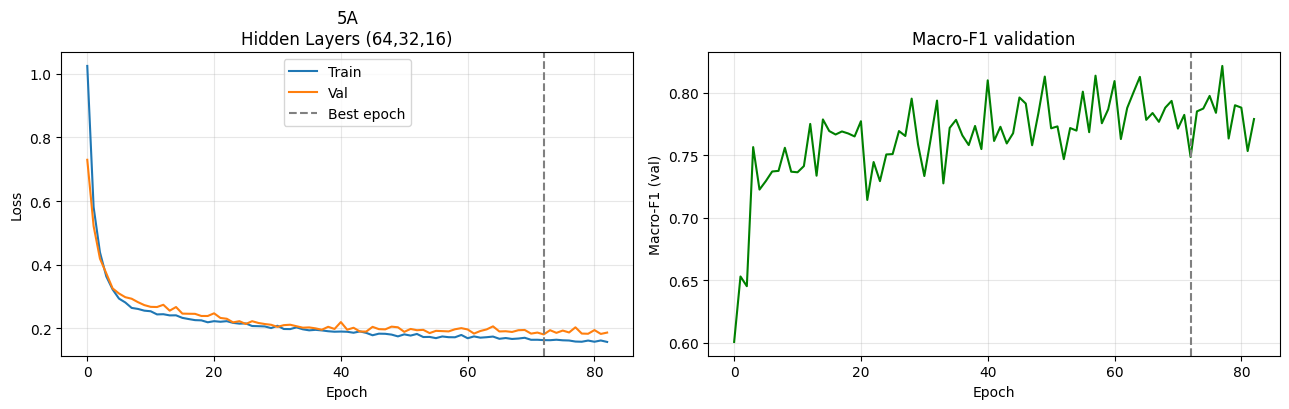

In [ ]:
r10 = run_experiment("5A", "Hidden Layers (64,32,16)", data=D2, hidden_sizes=(64, 32, 16), **T5)

The third one has three hidden layers, of sizes `(128,54,32)`

=== 5A | Hidden Layers (128,64,32) ===
Overall Accuracy: 0.939



,precision,recall,f1-score,support
Benign,0.992,0.935,0.963,2533.0
Brute Force,0.771,0.944,0.849,214.0
DoS Hulk,0.947,0.957,0.952,580.0
PortScan,0.296,0.930,0.449,43.0
macro avg,0.752,0.942,0.803,3370.0
weighted avg,0.962,0.939,0.947,3370.0


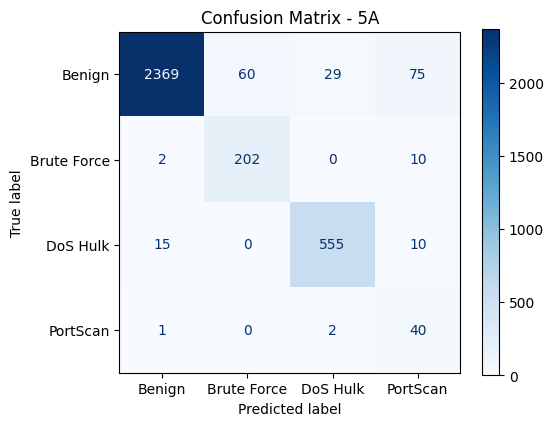

Best epoch: 54


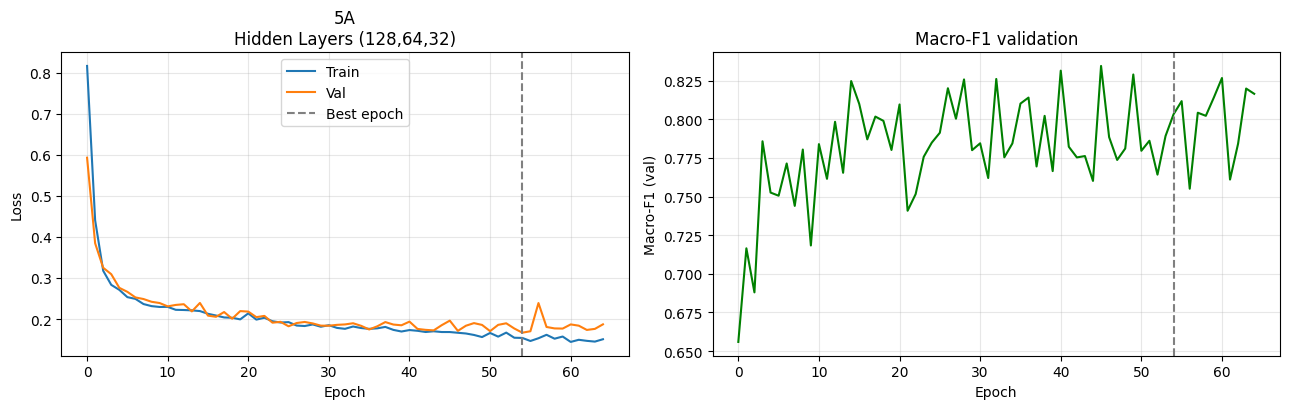

In [ ]:
r11 = run_experiment("5A", "Hidden Layers (128,64,32)", data=D2, hidden_sizes=(128, 64, 32), **T5)

## Task 5B
In this task, we modify the batch sizes in order to achieve a more complex model. We settle for three different batch sizes, training a model on each one.

The first batch size is 16

=== 5B | Batch size: 16 ===
Overall Accuracy: 0.939



,precision,recall,f1-score,support
Benign,0.985,0.938,0.961,2533.0
Brute Force,0.771,0.944,0.849,214.0
DoS Hulk,0.926,0.945,0.935,580.0
PortScan,0.375,0.907,0.531,43.0
macro avg,0.764,0.934,0.819,3370.0
weighted avg,0.954,0.939,0.944,3370.0


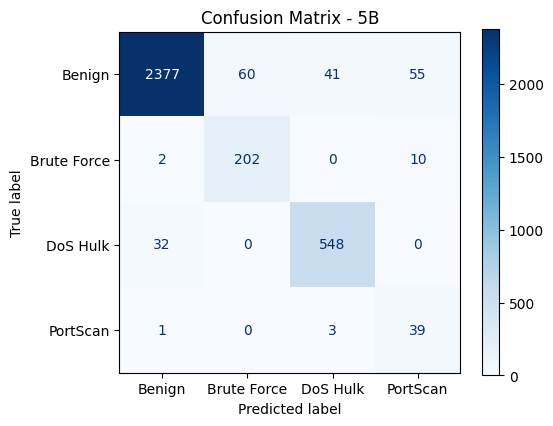

Best epoch: 43


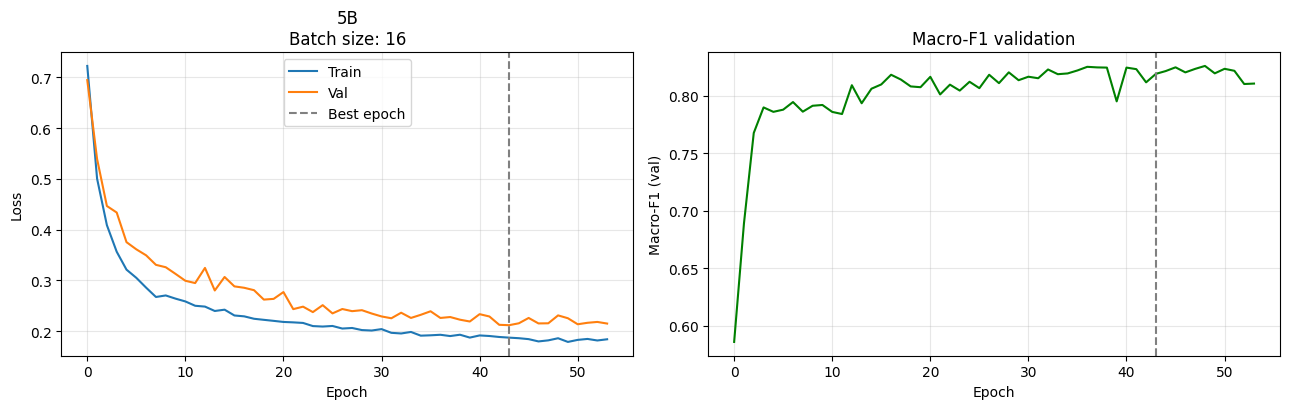

In [ ]:
r12   = run_experiment("5B", "Batch size: 16",   data=D2, batch_size=16,   **T5)

The second batch size is 1024

=== 5B | Batch size: 1024 ===
Overall Accuracy: 0.904



,precision,recall,f1-score,support
Benign,0.986,0.899,0.941,2533.0
Brute Force,0.748,0.944,0.835,214.0
DoS Hulk,0.974,0.907,0.939,580.0
PortScan,0.163,0.953,0.279,43.0
macro avg,0.718,0.926,0.748,3370.0
weighted avg,0.958,0.904,0.925,3370.0


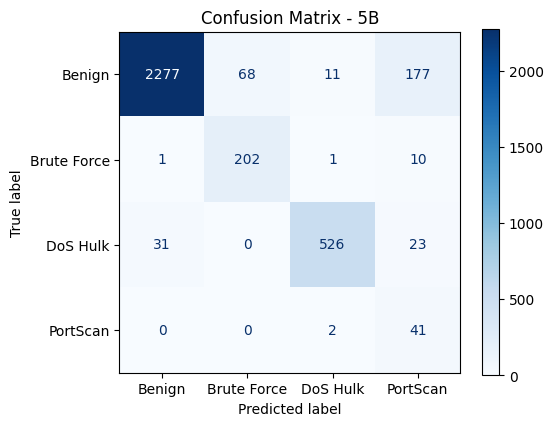

Best epoch: 299


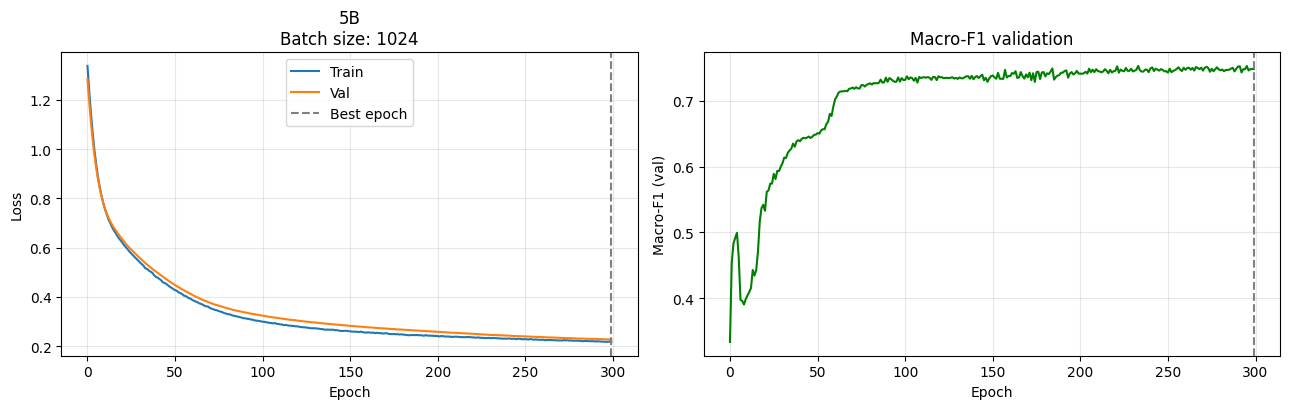

In [ ]:
r13 = run_experiment("5B", "Batch size: 1024", data=D2, batch_size=1024, **T5)

The third batch size is 128

=== 5B | Batch size: 128 ===
Overall Accuracy: 0.929



,precision,recall,f1-score,support
Benign,0.988,0.930,0.958,2533.0
Brute Force,0.774,0.944,0.851,214.0
DoS Hulk,0.954,0.921,0.937,580.0
PortScan,0.241,0.930,0.383,43.0
macro avg,0.739,0.931,0.782,3370.0
weighted avg,0.959,0.929,0.940,3370.0


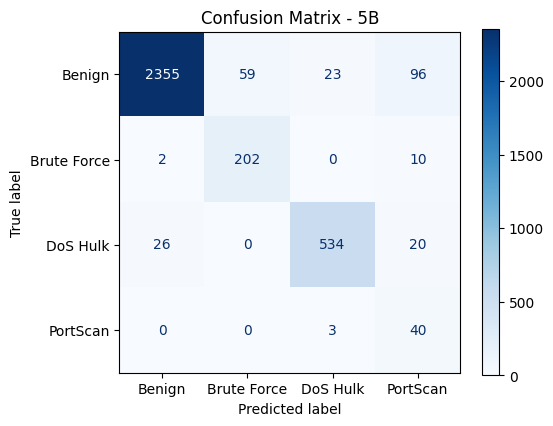

Best epoch: 146


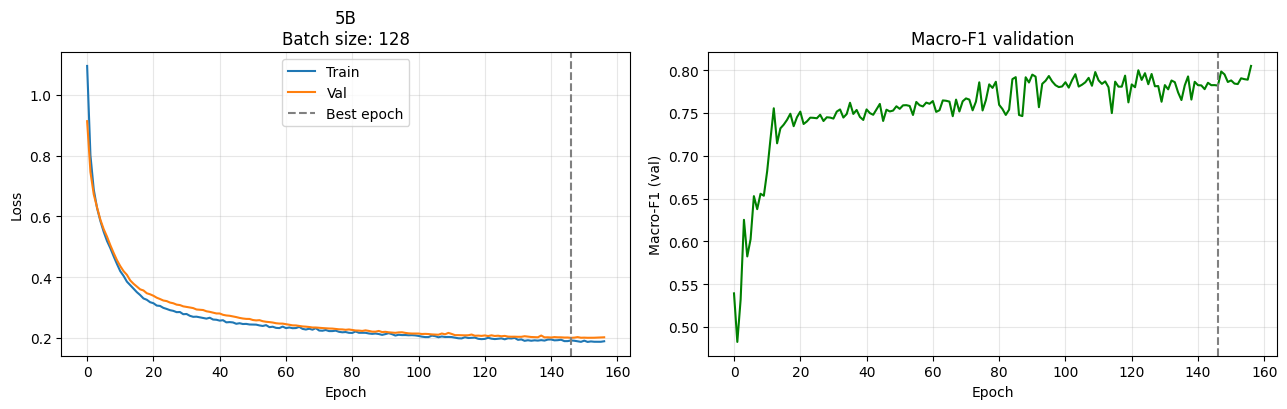

In [ ]:
r14 = run_experiment("5B", "Batch size: 128", data=D2, batch_size=128, **T5)

## Task 5C
In this task, we use different combinations of optimizer and learning rates.

Firstly, we train with standard SGD optimizer with $0.01$ learning rate

=== 5C1 | SGD (lr=0.01) ===
Overall Accuracy: 0.918



,precision,recall,f1-score,support
Benign,0.990,0.912,0.949,2533.0
Brute Force,0.754,0.944,0.838,214.0
DoS Hulk,0.941,0.933,0.937,580.0
PortScan,0.205,0.930,0.336,43.0
macro avg,0.722,0.930,0.765,3370.0
weighted avg,0.957,0.918,0.932,3370.0


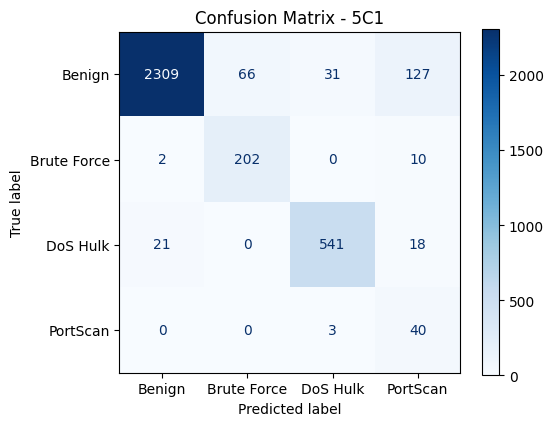

Best epoch: 297


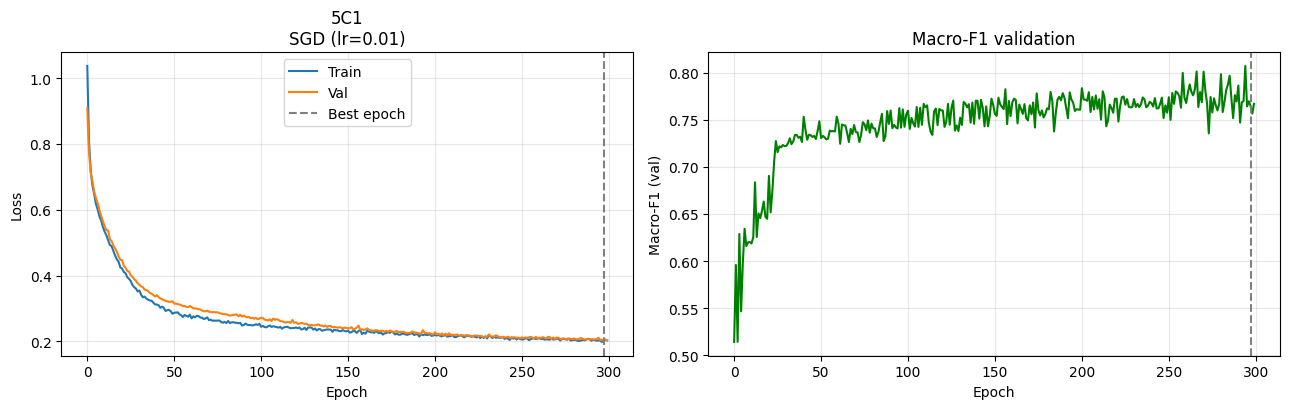

In [ ]:
r15 = run_experiment("5C1", "SGD (lr=0.01)", data=D2, optimizer="sgd", lr=0.01, momentum=0.0, **T5)

Secondly, we train with a higher learning rate of $0.1$ keeping the same optimizer

=== 5C2 | SGD (lr=0.1) ===
Overall Accuracy: 0.923



,precision,recall,f1-score,support
Benign,0.991,0.912,0.950,2533.0
Brute Force,0.771,0.944,0.849,214.0
DoS Hulk,0.892,0.966,0.927,580.0
PortScan,0.260,0.907,0.404,43.0
macro avg,0.728,0.932,0.782,3370.0
weighted avg,0.951,0.923,0.932,3370.0


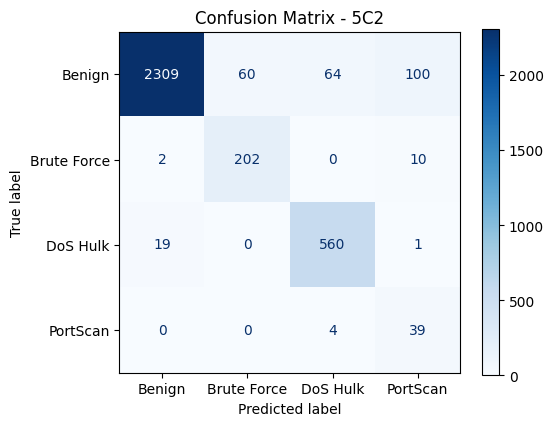

Best epoch: 35


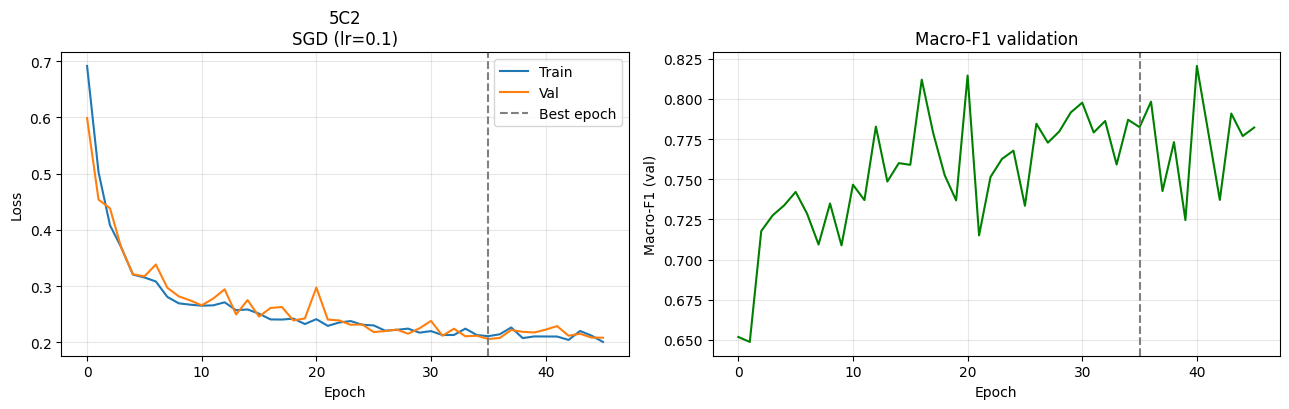

In [ ]:
r16 = run_experiment("5C2", "SGD (lr=0.1)", data=D2, optimizer="sgd", lr=0.1, momentum=0.0, **T5)

Next, we take the initial SGD setup and add a momentum factor of $0.9$

=== 5C3 | SGD + Momentum 0.9 (lr=0.01) ===
Overall Accuracy: 0.918



,precision,recall,f1-score,support
Benign,0.987,0.914,0.949,2533.0
Brute Force,0.751,0.944,0.836,214.0
DoS Hulk,0.957,0.921,0.938,580.0
PortScan,0.203,0.930,0.333,43.0
macro avg,0.725,0.927,0.764,3370.0
weighted avg,0.957,0.918,0.932,3370.0


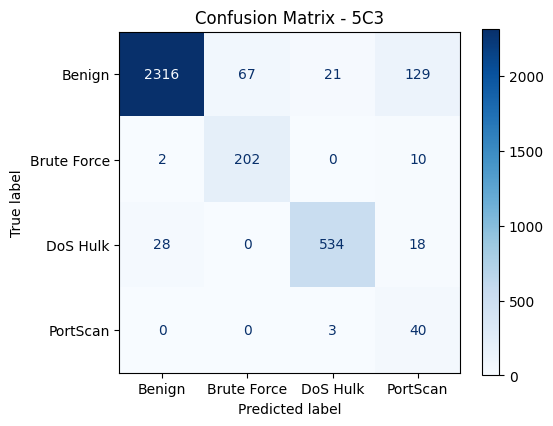

Best epoch: 41


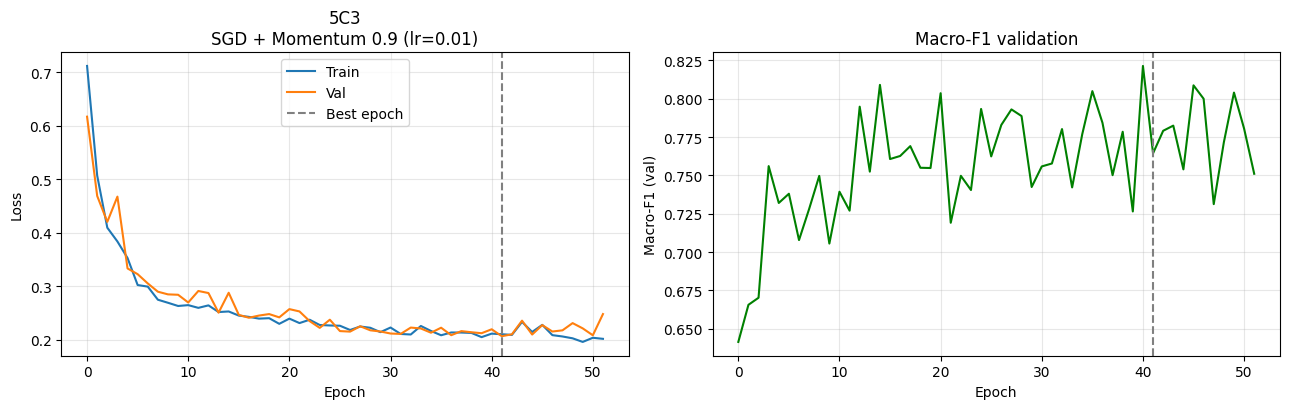

In [ ]:
r17 = run_experiment("5C3", "SGD + Momentum 0.9 (lr=0.01)", data=D2, optimizer="sgd", lr=0.01, momentum=0.9, **T5)

Finally, we use AdamW optimizer with learning rate $5 \times 10^{-3}$

=== 5C4 | AdamW (lr=5e-3) ===
Overall Accuracy: 0.903



,precision,recall,f1-score,support
Benign,0.993,0.887,0.937,2533.0
Brute Force,0.774,0.944,0.851,214.0
DoS Hulk,0.895,0.953,0.923,580.0
PortScan,0.175,0.930,0.295,43.0
macro avg,0.709,0.929,0.751,3370.0
weighted avg,0.952,0.903,0.921,3370.0


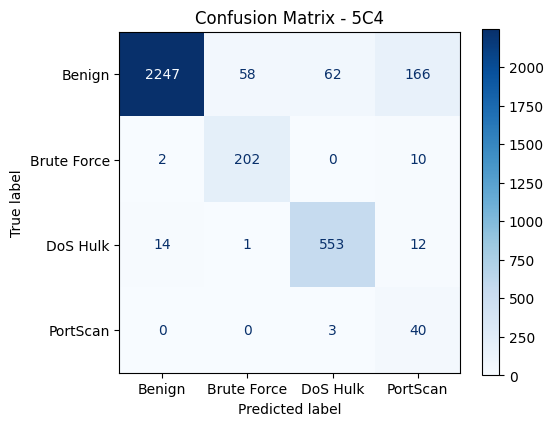

Best epoch: 23


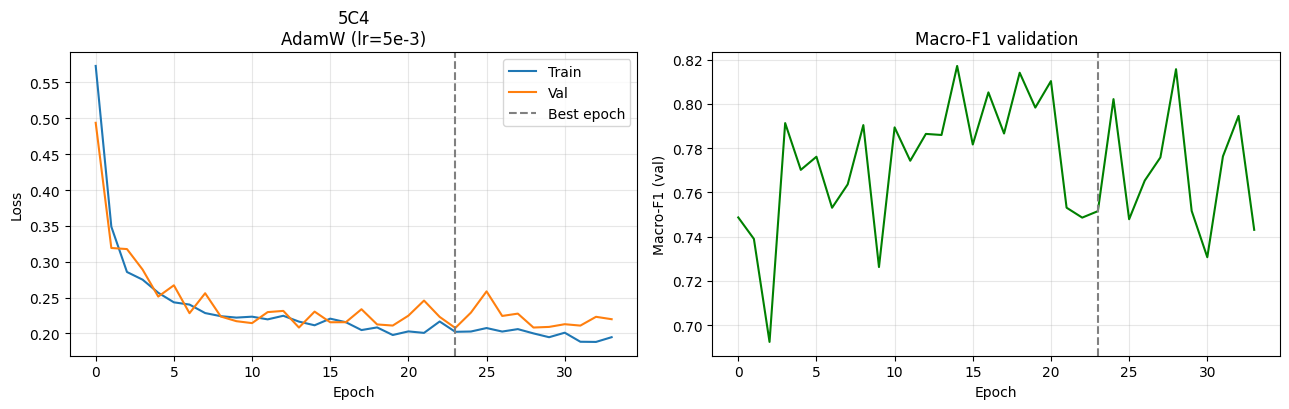

In [ ]:
r18 = run_experiment("5C4", "AdamW (lr=5e-3)", data=D2, lr=5e-3, **T5)

## Task 5D
We take the best model of the ones we trained in this task and put it against our initial baseline. The model of choice is `r12`

============ Baseline ============
--- TEST (loss 0.2870) ---


,precision,recall,f1-score,support
Benign,0.986,0.907,0.945,2534.00
Brute Force,0.762,0.944,0.843,214.00
DoS Hulk,0.951,0.903,0.927,580.00
PortScan,0.191,1.000,0.321,43.00
accuracy,0.910,0.910,0.910,0.91
macro avg,0.723,0.939,0.759,3371.00
weighted avg,0.956,0.910,0.927,3371.00


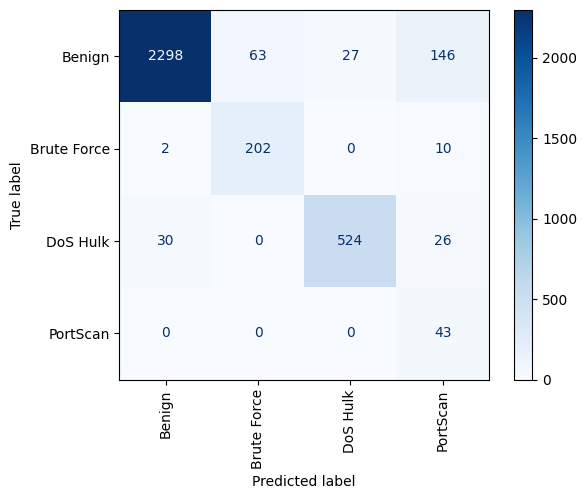

============ Competitor ============
--- TEST (loss 0.2590) ---


,precision,recall,f1-score,support
Benign,0.982,0.931,0.956,2534.000
Brute Force,0.765,0.944,0.845,214.000
DoS Hulk,0.905,0.936,0.920,580.000
PortScan,0.358,0.884,0.510,43.000
accuracy,0.932,0.932,0.932,0.932
macro avg,0.753,0.924,0.808,3371.000
weighted avg,0.947,0.932,0.937,3371.000


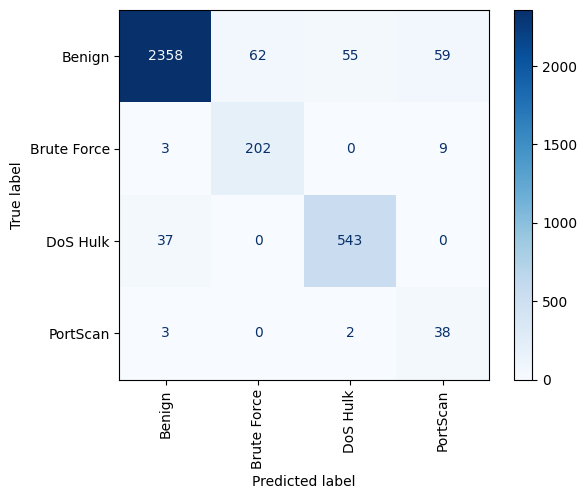

Comparison table


,Baseline,Competitor
loss,0.2870,0.2590
macro_F1,0.7590,0.8078
recall_Benign,0.9069,0.9305
recall_Brute Force,0.9439,0.9439
recall_DoS Hulk,0.9034,0.9362
recall_PortScan,1.0000,0.8837


In [ ]:
def compare_models(baseline, competitor):
  results = {}

  for name, exp in [("Baseline", baseline),
                    ("Competitor", competitor)]:
      print("=" * 12, name, "=" * 12)
      results[name] = eval_split(exp["model"], D2, "test")

  results_df = pd.DataFrame({
      name: [res["loss"], res["macro_f1"], *res["recall"]]
      for name, res in results.items()
  }, index=["loss", "macro_F1"] + [f"recall_{n}" for n in D2["class_names"]])
  results_df.index.name = None

  print("Comparison table")
  display(results_df.round(4))
compare_models(r8, r12)

## Task 6
This task deals with overfitting problems and how to minimize them.

We start from a new baseline (as specified by the lab document) and train it

=== 6A | Large 5-layer network (no regularization, no early stopping) ===
Overall Accuracy: 0.968



,precision,recall,f1-score,support
Benign,0.993,0.965,0.979,2533.0
Brute Force,0.891,0.991,0.938,214.0
DoS Hulk,0.929,0.976,0.952,580.0
PortScan,0.635,0.930,0.755,43.0
macro avg,0.862,0.965,0.906,3370.0
weighted avg,0.971,0.968,0.969,3370.0


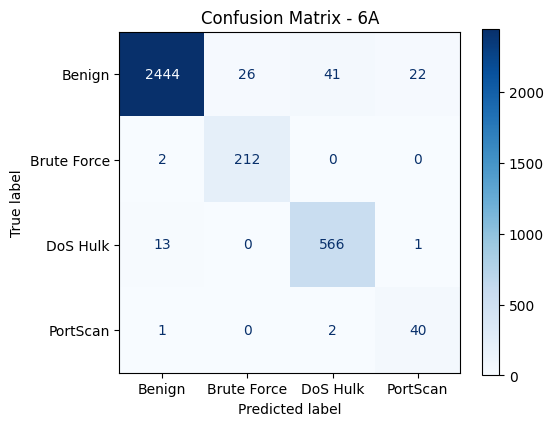

Best epoch: 82


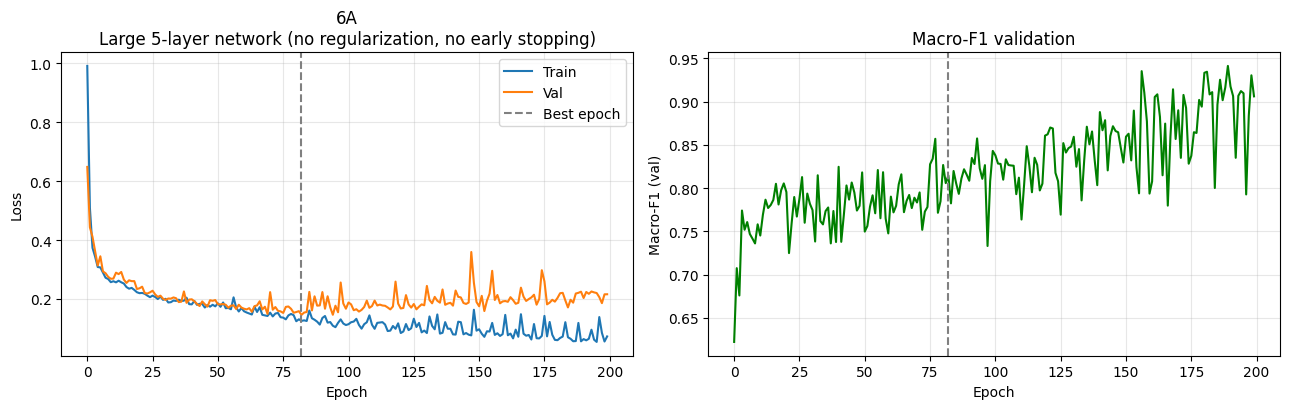

In [ ]:
T6 = dict(class_weight="balanced", weight_decay=0.0,
          restore_best=False, patience=10**9,
          epochs=200, batch_size=128, hidden_sizes=(256, 128, 64, 32, 16))
r19 = run_experiment("6A", "Large 5-layer network (no regularization, no early stopping)", data=D2, **T6)

To confirm the presence of overfitting, we use the `eval_split` function to create a comparison table

--- TRAIN (loss 0.0934) ---


,precision,recall,f1-score,support
Benign,0.995,0.960,0.977,11822.000
Brute Force,0.862,0.998,0.925,999.000
DoS Hulk,0.919,0.976,0.947,2708.000
PortScan,0.698,1.000,0.822,199.000
accuracy,0.966,0.966,0.966,0.966
macro avg,0.869,0.984,0.918,15728.000
weighted avg,0.970,0.966,0.967,15728.000


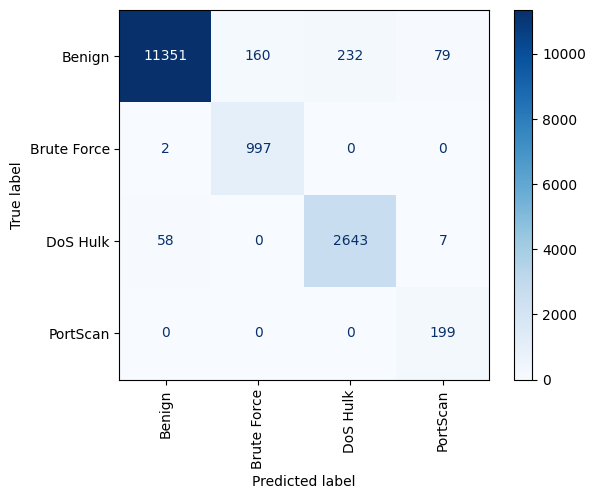

--- VAL (loss 0.1669) ---


,precision,recall,f1-score,support
Benign,0.993,0.965,0.979,2533.000
Brute Force,0.891,0.991,0.938,214.000
DoS Hulk,0.929,0.976,0.952,580.000
PortScan,0.635,0.930,0.755,43.000
accuracy,0.968,0.968,0.968,0.968
macro avg,0.862,0.965,0.906,3370.000
weighted avg,0.971,0.968,0.969,3370.000


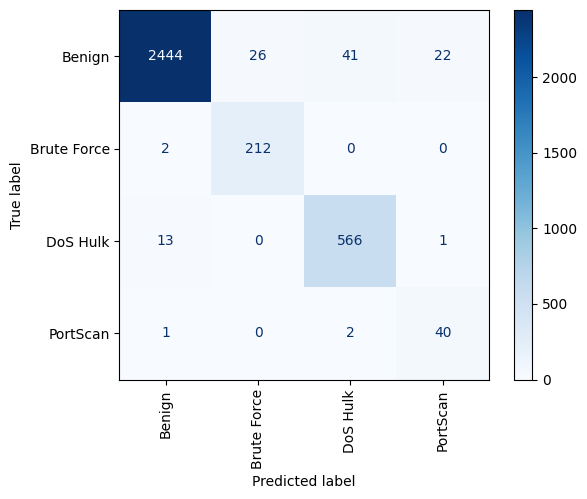

,train,val,gap
loss,0.0934,0.1669,0.0735
macro_F1,0.9178,0.9060,-0.0118
recall_Benign,0.9602,0.9649,0.0047
recall_Brute Force,0.9980,0.9907,-0.0073
recall_DoS Hulk,0.9760,0.9759,-0.0001
recall_PortScan,1.0000,0.9302,-0.0698


In [ ]:
train_res = eval_split(r19["model"], D2, "train")
val_res = eval_split(r19["model"], D2, "val")

overfitting_df = pd.DataFrame({
    "train": [train_res["loss"], train_res["macro_f1"], *train_res["recall"]],
    "val": [val_res["loss"], val_res["macro_f1"], *val_res["recall"]]
}, index=["loss", "macro_F1"] + [f"recall_{n}" for n in D2["class_names"]]).round(4)

overfitting_df["gap"] = (overfitting_df["val"] - overfitting_df["train"]).round(4)
overfitting_df.index.name = None

display(overfitting_df)

Now that we confirmed overfitting, we can start mitigating it. The first countermeasure we implement is early stopping. We define a new configuration `T6A`

=== 6B | Early stopping ===
Overall Accuracy: 0.936



,precision,recall,f1-score,support
Benign,0.992,0.937,0.964,2533.0
Brute Force,0.792,0.944,0.861,214.0
DoS Hulk,0.966,0.929,0.947,580.0
PortScan,0.241,0.930,0.383,43.0
macro avg,0.748,0.935,0.789,3370.0
weighted avg,0.966,0.936,0.947,3370.0


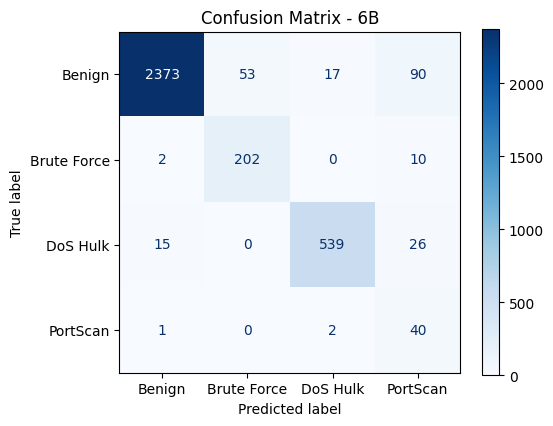

Best epoch: 69


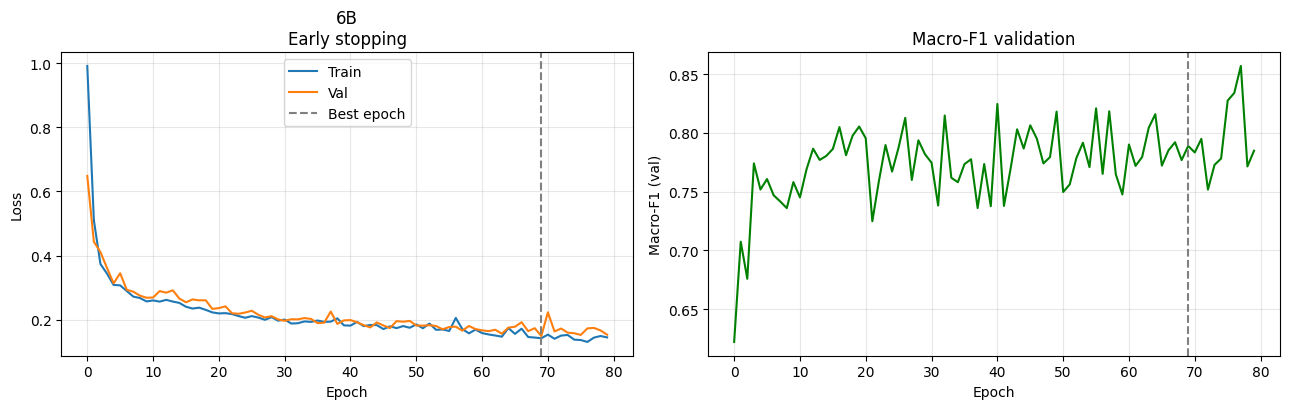

In [ ]:
T6A = {**T6, "patience": 10, "restore_best": True}

r20 = run_experiment("6B", "Early stopping", data=D2, **T6A)

Then, we introduce a lower weight decay of $0.01$

=== 6D | Weight decay (0.01) with early stopping ===
Overall Accuracy: 0.932



,precision,recall,f1-score,support
Benign,0.993,0.931,0.961,2533.0
Brute Force,0.786,0.944,0.858,214.0
DoS Hulk,0.966,0.933,0.949,580.0
PortScan,0.226,0.930,0.364,43.0
macro avg,0.743,0.935,0.783,3370.0
weighted avg,0.965,0.932,0.945,3370.0


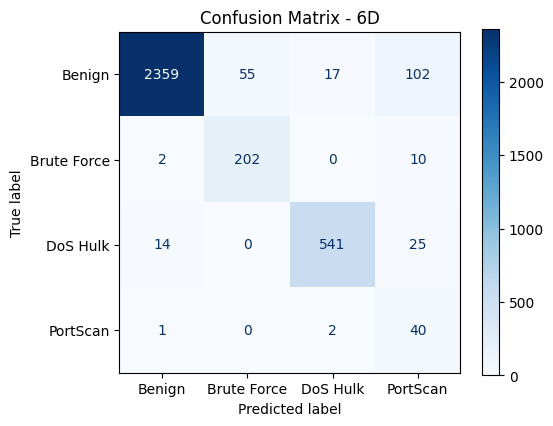

Best epoch: 69


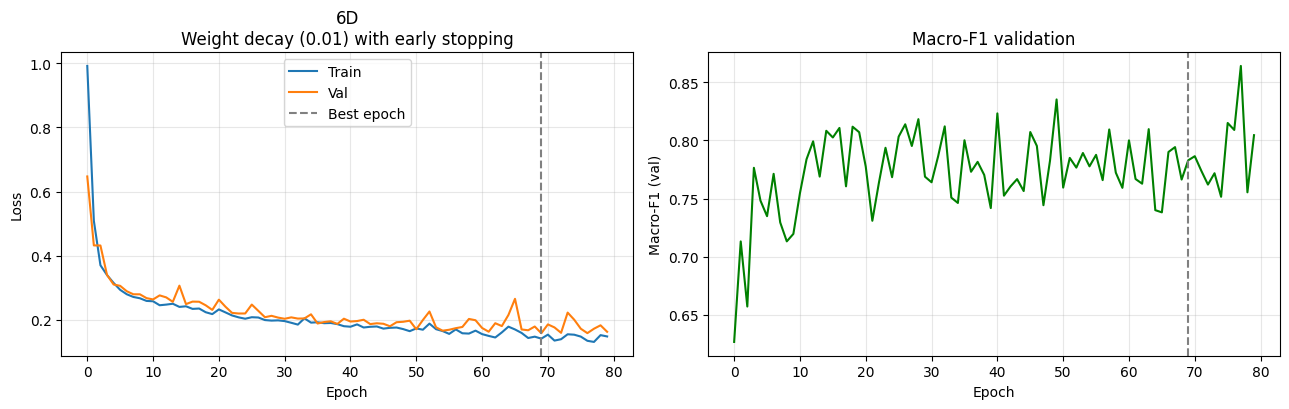

In [ ]:
r21 = run_experiment("6D", "Weight decay (0.01) with early stopping", data=D2, **{**T6A, "weight_decay": 0.01})

This configuration will become our baseline for our next experiment. We introduce dropout layers, with probability $24\%$

=== 6E | Dropout (0.24) with early stopping and weight decay ===
Overall Accuracy: 0.897



,precision,recall,f1-score,support
Benign,0.992,0.875,0.930,2533.0
Brute Force,0.757,0.944,0.840,214.0
DoS Hulk,0.735,0.974,0.838,580.0
PortScan,0.390,0.907,0.545,43.0
macro avg,0.718,0.925,0.788,3370.0
weighted avg,0.925,0.897,0.904,3370.0


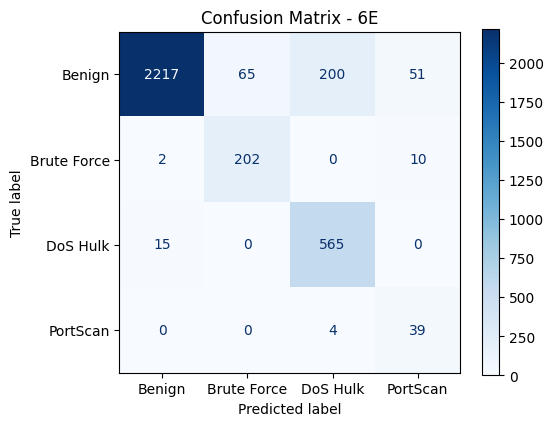

Best epoch: 44


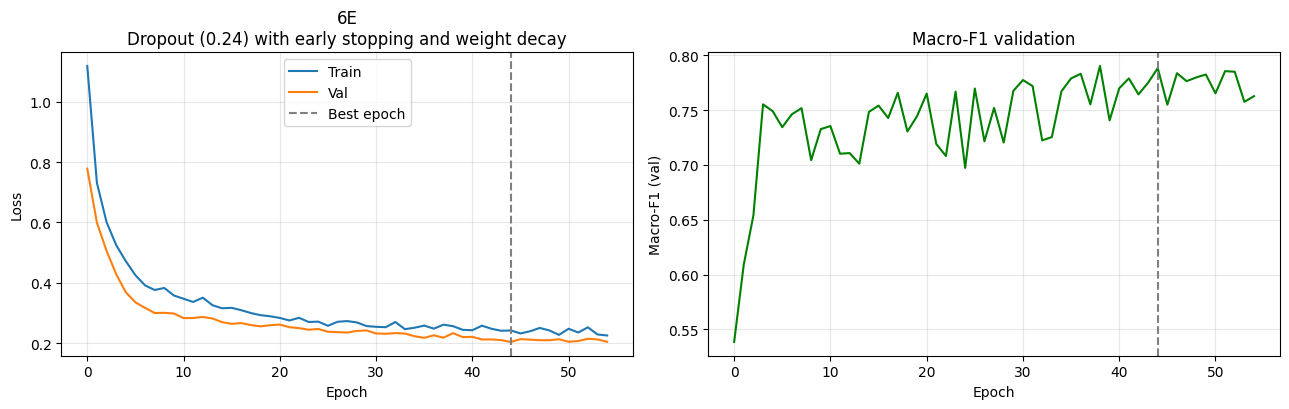

In [ ]:
T6B = {**T6A, "weight_decay": 0.01}

r22 = run_experiment("6E", "Dropout (0.24) with early stopping and weight decay", data=D2, **{**T6B, "dropout": 0.24})

In this section we add batch normalization to the previous configuration

=== 6F | Added Batch Normalization ===
Overall Accuracy: 0.915



,precision,recall,f1-score,support
Benign,0.991,0.900,0.943,2533.0
Brute Force,0.740,0.944,0.830,214.0
DoS Hulk,0.818,0.967,0.886,580.0
PortScan,0.355,0.907,0.510,43.0
macro avg,0.726,0.930,0.792,3370.0
weighted avg,0.937,0.915,0.921,3370.0


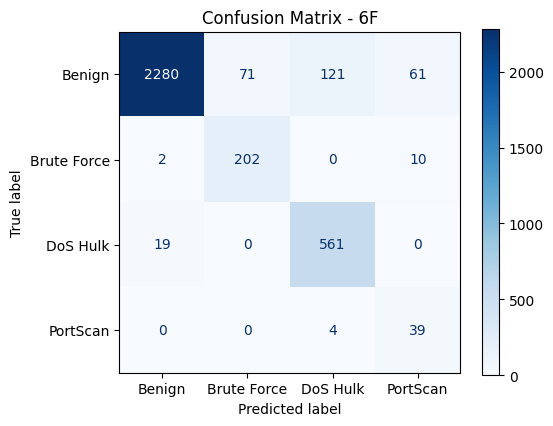

Best epoch: 38


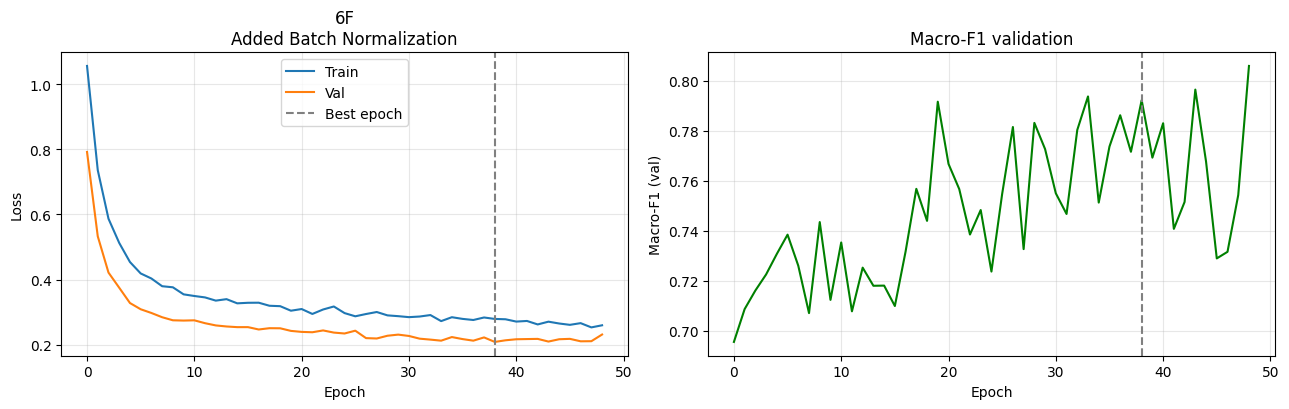

In [ ]:
r23 = run_experiment("6F", "Added Batch Normalization", data=D2, **{**T6B, "dropout": 0.24, "batchnorm": True})

Finally, we reduce the network size (on top of all previous improvements)

=== 6C | Single 64-unit hidden layer) ===
Overall Accuracy: 0.934



,precision,recall,f1-score,support
Benign,0.990,0.933,0.961,2533.0
Brute Force,0.765,0.944,0.845,214.0
DoS Hulk,0.928,0.933,0.930,580.0
PortScan,0.296,0.930,0.449,43.0
macro avg,0.745,0.935,0.796,3370.0
weighted avg,0.956,0.934,0.942,3370.0


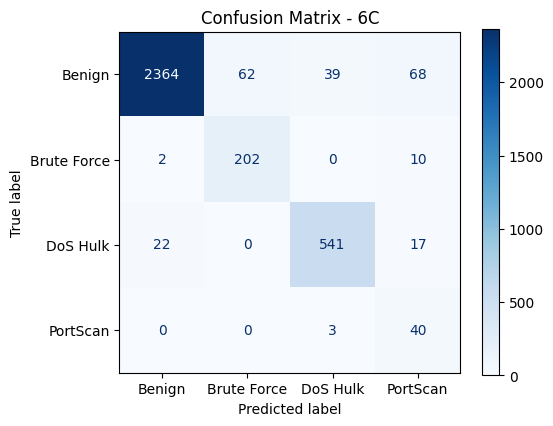

Best epoch: 173


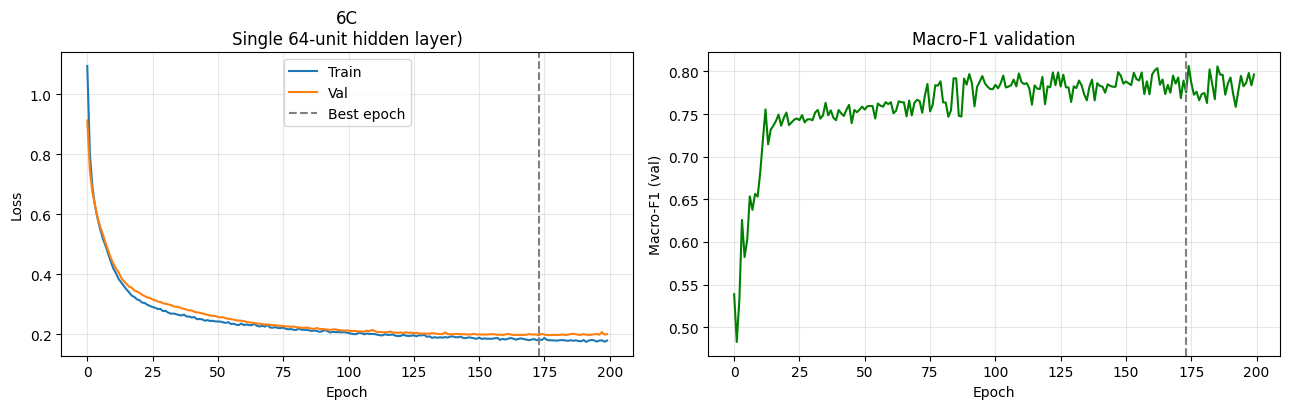

In [ ]:
r24 = run_experiment("6C", "Single 64-unit hidden layer)", data=D2, **{**T6, "hidden_sizes": (64,)})

In conclusion, we provide the comparison between the baseline of task 4 `r8` and the our latest experiment `r24`

============ Baseline ============
--- TEST (loss 0.2870) ---


,precision,recall,f1-score,support
Benign,0.986,0.907,0.945,2534.00
Brute Force,0.762,0.944,0.843,214.00
DoS Hulk,0.951,0.903,0.927,580.00
PortScan,0.191,1.000,0.321,43.00
accuracy,0.910,0.910,0.910,0.91
macro avg,0.723,0.939,0.759,3371.00
weighted avg,0.956,0.910,0.927,3371.00


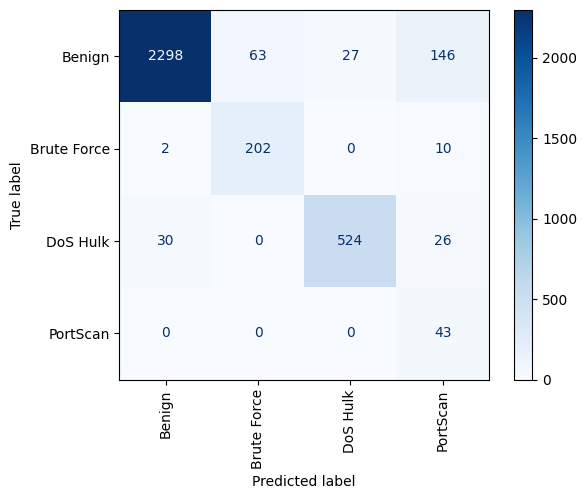

============ Competitor ============
--- TEST (loss 0.2210) ---


,precision,recall,f1-score,support
Benign,0.990,0.929,0.958,2534.000
Brute Force,0.780,0.944,0.854,214.000
DoS Hulk,0.912,0.924,0.918,580.000
PortScan,0.279,0.953,0.432,43.000
accuracy,0.929,0.929,0.929,0.929
macro avg,0.740,0.938,0.790,3371.000
weighted avg,0.954,0.929,0.938,3371.000


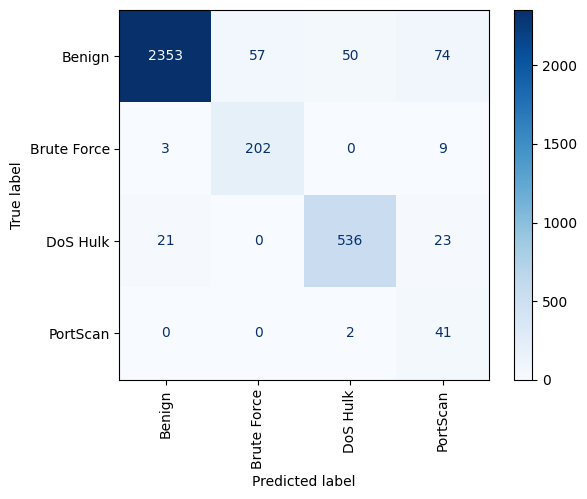

Comparison table


,Baseline,Competitor
loss,0.2870,0.2210
macro_F1,0.7590,0.7904
recall_Benign,0.9069,0.9286
recall_Brute Force,0.9439,0.9439
recall_DoS Hulk,0.9034,0.9241
recall_PortScan,1.0000,0.9535


In [ ]:
compare_models(baseline=r8, competitor=r24)